# Imports

## Import the folder for compatibility (if running local)

In [2]:
import os
import sys

project_root = "Incremental-Learning-MycroftMinds"
cwd = os.path.abspath(os.getcwd())
while True:
    if os.path.basename(cwd) == project_root:
        if cwd not in sys.path:
            sys.path.insert(0, cwd)
        break
    parent = os.path.dirname(cwd)
    if parent == cwd:
        raise FileNotFoundError(f"Project root '{project_root}' not found in any parent directory.")
    cwd = parent

## Import external libs and internal models

In [3]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm

from src.data.io import load_dataset
from src.utils.memory import calculate_memory_usage
from src.utils.utils import get_device_data
from src.evaluation.metrics import calculate_metrics, all_time_aggregation_metrics
from src.evaluation.visualization import plot_part_predictions, plot_hourly_predictions
from src.evaluation.training import all_valid_splits_seq_fit_predict, test_set_seq_fit_predict

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from river.forest import ARFRegressor
from river.tree import HoeffdingTreeRegressor
from src.evaluation.baseline import PreviousValueRegressor, SeasonalMeanRegressor
from src.trees import fastodt
from src.bagging import ARFRegressorFODT
from src.boosting import IncubationBoost
from src.ensemble_methods import elasticGBDT

import ipywidgets as widgets
widgets.IntSlider()

IntSlider(value=0)

# Download the splitted data

In [4]:
# check you data dir and file prefixes
data_dir = '../../data/first_batch'

## Pick the hourly or 5-min granularity data
- WFV, train+=28 (train set increasing), validation=28, hourly granularity
- WFV, train+=28 (train set increasing), validation=28, 5-min granularity

## Evaluation Settings

In [5]:
DATA_FREQUENCY = 'H' # '15min'
FORECAST_HORIZON = '1h'
SPIKE_PROMINENCE = 10

In [6]:
# Measure loading time
start_time = time.time()

# Load data

train, valid, test = load_dataset(data_dir=data_dir, prefix='dev_4_1h_wfv', use_numpy=True)
FEATURES = ['time', 'device_id', 'hour', 'weekday', 'month', 
                'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 
                'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 
                'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 
                'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 
                'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_react_power_lag_1h', 'L2_react_power_lag_24h', 
                'L2_voltage_lag_1h', 'L2_voltage_lag_24h', 
                'L3_act_power_lag_1h', 'L3_act_power_lag_24h', 'L3_app_power_lag_1h', 'L3_app_power_lag_24h', 
                'L3_current_lag_1h', 'L3_current_lag_24h', 'L3_react_power_lag_1h', 'L3_react_power_lag_24h', 
                'L3_voltage_lag_1h', 'L3_voltage_lag_24h', 
                'grid_freq_lag_1h', 'grid_freq_lag_24h', 
                'powerfactor1_lag_1h', 'powerfactor1_lag_24h', 
                'powerfactor2_lag_1h', 'powerfactor2_lag_24h', 
                'powerfactor3_lag_1h', 'powerfactor3_lag_24h']

loading_time = time.time() - start_time
print(f"Data loaded in {loading_time/60:.2f} minutes")

[INFO] Loading train data...
[INFO] Train data loaded: 7 samples
[INFO] Loading valid data...
[INFO] Valid data loaded: 7 samples
[INFO] Loading test data...
[INFO] Test data loaded: 2 samples
Data loaded in 0.05 minutes


## Data structure information

The data structure is as follows:
- For walk-forward validation:
  - `train` is a list of tuples, where each tuple is (X, y) for one split
  - `valid` is a list of tuples, where each tuple is (X, y) for one split
  - `test` is a tuple of (X, y)
- Each X array contains:
  - Column 0: `time` (`pandas.Timedelta`)
  - Column 1: `device_id` (`str`)
  - Other columns: time-related features and lag features

The memory usage of the loaded data is printed below:

In [7]:
# Print data structure and memory usage information
if isinstance(train, list):
    print(f"Training data: {len(train)} splits")
    print(f"Validation data: {len(valid)} splits")
    
    # Show first split shape
    print(f"First train split shape: X={train[0][0].shape}, y={train[0][1].shape}")
    print(f"First valid split shape: X={valid[0][0].shape}, y={valid[0][1].shape}")
    
    # Memory usage
    train_mem = sum(calculate_memory_usage(ts) for ts in train)
    valid_mem = sum(calculate_memory_usage(vs) for vs in valid)
    test_mem = calculate_memory_usage(test)
    
    print(f"\nMemory usage:")
    print(f"Train: {train_mem:.2f} MB")
    print(f"Valid: {valid_mem:.2f} MB")
    print(f"Test: {test_mem:.2f} MB")
    print(f"Total: {train_mem + valid_mem + test_mem:.2f} MB")
else:
    # For non-list structure
    print(f"Training data shape: X={train[0].shape}, y={train[1].shape}")
    print(f"Validation data shape: X={valid[0].shape}, y={valid[1].shape}")
    print(f"Test data shape: X={test[0].shape}, y={test[1].shape}")

Training data: 7 splits
Validation data: 7 splits
First train split shape: X=(672, 43), y=(672,)
First valid split shape: X=(672, 43), y=(672,)

Memory usage:
Train: 6.32 MB
Valid: 1.40 MB
Test: 0.41 MB
Total: 8.13 MB


# WFV Model Evaluation
(train+valid WFV)
- (1) `train[0]` vs `valid[0]`
- (2) `train[1]` vs `valid[1]`
- ...
- (n) `train[n]` vs `valid[n]`

, where: 
$$ train[1] = train[0]+valid[0] $$
$$...$$
$$ train[n] = train[0]+valid[0]+valid[1]+...+valid[n-1] $$

## Hourly granularity

### Baseline model (seasonal averages)

In [8]:
update_freq = "14D"
bl_mean = SeasonalMeanRegressor
bl_mean_params = {}

In [9]:
bl_mean_train_period_predictions, bl_mean_valid_period_predictions,\
bl_mean_train_period_metrics, bl_mean_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=bl_mean,
    model_params=bl_mean_params,
    train=train,
    valid=valid,
    incremental=False,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 14:00:00+02:00 to 2022-10-18 13:00:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2022-10-18 14:00:00+02:00 to 2022-11-01 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-20 14:00:00+02:00 to 2022-11-01 13:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2022-11-01 14:00:00+01:00 to 2022-11-15 12:00:00+01:00

-------------------------
Model's memory usage: 0.024620 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-18 14:00:00+02:00 - 2022-11-15 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.4526
	MAE: 0.3524
	MAPE: 40.6795%

Directional Metrics:
	Directional Accuracy: 62.1461%
	First-Diff Correlation: 0.2992

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 14:00:00+02:00 to 2022-11-15 12:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2022-11-15 13:00:00+01:00 to 2022-11-29 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-20 14:00:00+02:00 to 2022-11-29 13:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2022-11-29 14:00:00+01:00 to 2022-12-13 12:00:00+01:00

-------------------------
Model's memory usage: 0.024483 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 13:00:00+01:00 - 2022-12-13 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.4008
	MAE: 0.3024
	MAPE: 52.8434%

Directional Metrics:
	Directional Accuracy: 61.9970%
	First-Diff Correlation: 0.5385

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 14:00:00+02:00 to 2023-03-07 12:00:00+01:00

Time: 0.01 seconds
Predicting for chunk from 2023-03-07 13:00:00+01:00 to 2023-03-21 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-20 14:00:00+02:00 to 2023-03-21 13:00:00+01:00

Time: 0.02 seconds
Predicting for chunk from 2023-03-21 14:00:00+01:00 to 2023-04-04 13:00:00+02:00

-------------------------
Model's memory usage: 0.024391 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-07 13:00:00+01:00 - 2023-04-04 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2840
	MAE: 0.1963
	MAPE: 44.6998%

Directional Metrics:
	Directional Accuracy: 60.0596%
	First-Diff Correlation: 0.5357

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.3158
		Recall: 0.3158
		F1: 0.3158
	Drops:
		Precision: 0.1000
		Recall: 0.1000
		F1: 0.1000

Delayed Detection (

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 14:00:00+02:00 to 2023-04-04 13:00:00+02:00

Time: 0.01 seconds
Predicting for chunk from 2023-04-04 14:00:00+02:00 to 2023-04-10 04:00:00+02:00

-------------------------
Model's memory usage: 0.024376 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-04 14:00:00+02:00 - 2023-04-10 04:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3863
	MAE: 0.2343
	MAPE: 88.7863%

Directional Metrics:
	Directional Accuracy: 55.2239%
	First-Diff Correlation: 0.4481

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.3333
		Recall: 0.3333
		F1: 0.3333
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
------------------------------------------

#### Results

In [10]:
print("\n\nValid period metrics:")
bl_mean_all_time_valid_metrics = all_time_aggregation_metrics(bl_mean_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.3445 ± 0.0635
	MAE: 0.2449 ± 0.0581
	MAPE: 57.0507% ± 14.5529%

	Directional Metrics:
		Directional Accuracy: 61.4765% ± 6.6599%
		First-Diff Correlation: 0.5626 ± 0.1451

	Immediate Detection (delta=0):
		Spike Precision: 0.1654 ± 0.2037
		Spike Recall: 0.1875 ± 0.2503
		Spike F1: 0.1751 ± 0.2239
		Drop Precision: 0.0643 ± 0.0789
		Drop Recall: 0.0749 ± 0.0976
		Drop F1: 0.0689 ± 0.0867

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4486 ± 0.2359
		Spike Recall: 0.4531 ± 0.3049
		Spike F1: 0.4443 ± 0.2685
		Drop Precision: 0.1000 ± 0.1035
		Drop Recall: 0.1114 ± 0.1158
		Drop F1: 0.1050 ± 0.1084
Daily Metrics:
	RMSE: 5.2474 ± 1.2989
	MAE: 4.1663 ± 1.1075
	MAPE: 39.0060% ± 14.1589%

	Directional Metrics:
		Directional Accuracy: 73.2993% ± 5.2031%
		First-Diff Correlation: 0.7948 ± 0.1372

	Immediate Detection (delta=0

#### Validation plots

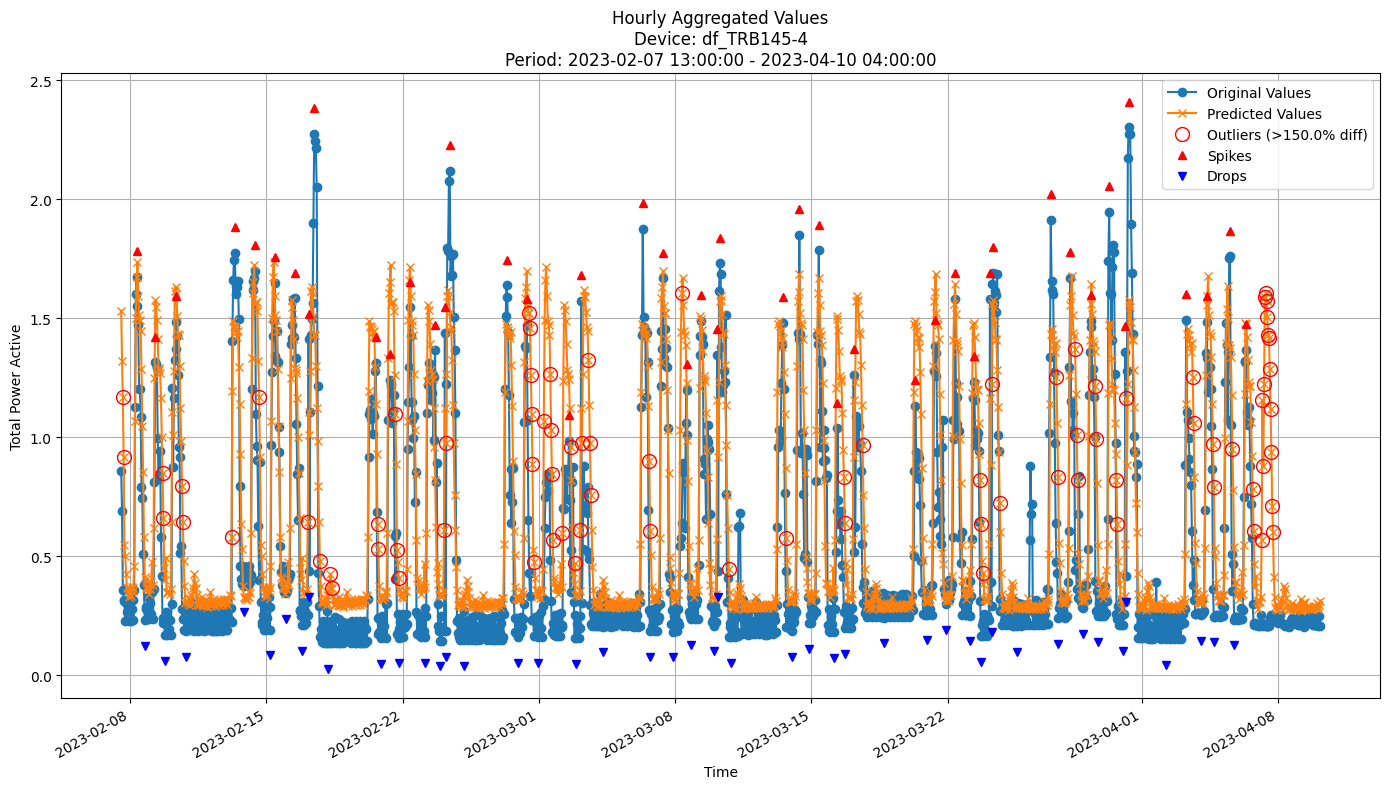


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2983
MAE: 0.2074
MAPE: 56.5429%

Directional Metrics:
Directional Accuracy: 56.6306%
First-Diff Correlation: 0.5930

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2791
  Recall: 0.2609
  F1 Score: 0.2697
Drops:
  Precision: 0.0465
  Recall: 0.0444
  F1 Score: 0.0455

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.6047
  Recall: 0.5652
  F1 Score: 0.5843
Drops:
  Precision: 0.1628
  Recall: 0.1556
  F1 Score: 0.1591


In [11]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in bl_mean_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, bl_mean_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, bl_mean_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### Baseline model (predict previous value)

In [12]:
update_freq = "1H"
bl_prev = PreviousValueRegressor
bl_prev_params = {}

In [13]:
bl_prev_train_period_predictions, bl_prev_valid_period_predictions,\
bl_prev_train_period_metrics, bl_prev_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=bl_prev,
    model_params=bl_prev_params,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 14:00:00+02:00 to 2022-10-18 13:00:00+02:00
Model's memory usage: 0.000420 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-18 14:00:00+02:00 - 2022-11-15 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2575
	MAE: 0.1510
	MAPE: 17.5130%

Directional Metrics:
	Directional Accuracy: 34.4262%
	First-Diff Correlation: -0.0298

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
---------------------------------------------

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 14:00:00+02:00 to 2022-11-15 12:00:00+01:00
Model's memory usage: 0.000412 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 13:00:00+01:00 - 2022-12-13 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2538
	MAE: 0.1422
	MAPE: 23.3583%

Directional Metrics:
	Directional Accuracy: 39.6423%
	First-Diff Correlation: 0.2422

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
----------------------------------------------

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 14:00:00+02:00 to 2023-03-07 12:00:00+01:00
Model's memory usage: 0.000381 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-07 13:00:00+01:00 - 2023-04-04 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2420
	MAE: 0.1427
	MAPE: 30.5933%

Directional Metrics:
	Directional Accuracy: 37.4069%
	First-Diff Correlation: -0.0237

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
---------------------------------------------

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 14:00:00+02:00 to 2023-04-04 13:00:00+02:00
Model's memory usage: 0.000374 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-04 14:00:00+02:00 - 2023-04-10 04:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1473
	MAE: 0.0628
	MAPE: 11.6539%

Directional Metrics:
	Directional Accuracy: 40.2985%
	First-Diff Correlation: 0.4767

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
----------------------------------------------

#### Results

In [14]:
print("\n\nValid period metrics:")
bl_prev_all_time_valid_metrics = all_time_aggregation_metrics(bl_prev_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2270 ± 0.0423
	MAE: 0.1280 ± 0.0315
	MAPE: 23.8618% ± 7.5965%

	Directional Metrics:
		Directional Accuracy: 39.1825% ± 4.8386%
		First-Diff Correlation: 0.1865 ± 0.1993

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.8571 ± 0.3499
		Spike Recall: 0.8571 ± 0.3499
		Spike F1: 0.8571 ± 0.3499
		Drop Precision: 0.8482 ± 0.3470
		Drop Recall: 0.8571 ± 0.3499
		Drop F1: 0.8525 ± 0.3482
Daily Metrics:
	RMSE: 0.3571 ± 0.0446
	MAE: 0.1464 ± 0.0140
	MAPE: 1.7122% ± 0.7817%

	Directional Metrics:
		Directional Accuracy: 94.0476% ± 6.5205%
		First-Diff Correlation: 0.9991 ± 0.0003

	Immediate Detection (delta=0):


#### Validation plots

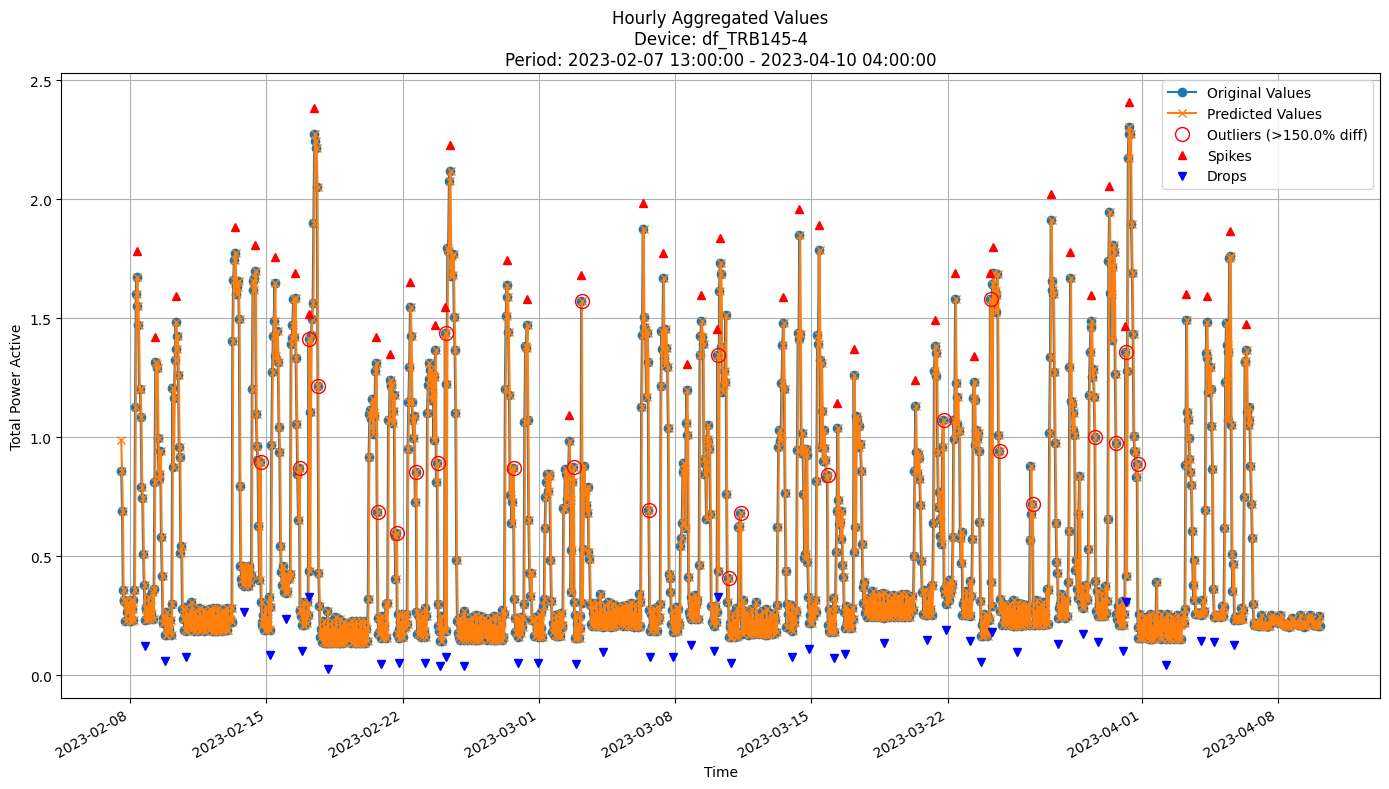


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2333
MAE: 0.1327
MAPE: 29.8270%

Directional Metrics:
Directional Accuracy: 36.9418%
First-Diff Correlation: -0.0126

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


In [15]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in bl_prev_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, bl_prev_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, bl_prev_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### GBDT

In [16]:
update_freq = "14D"  # Update the model every 14 days

gbdt = GradientBoostingRegressor
gbdt_params = dict(n_estimators=100, learning_rate=0.03, subsample=0.8, max_depth=10, random_state=42)

In [17]:
gbdt_train_period_predictions, gbdt_valid_period_predictions, \
gbdt_train_period_metrics, gbdt_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=gbdt, 
    model_params=gbdt_params, 
    train=train, 
    valid=valid, 
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 14:00:00+02:00 to 2022-10-18 13:00:00+02:00

Time: 1.49 seconds
Predicting for chunk from 2022-10-18 14:00:00+02:00 to 2022-11-01 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-20 14:00:00+02:00 to 2022-11-01 13:00:00+01:00

Time: 2.18 seconds
Predicting for chunk from 2022-11-01 14:00:00+01:00 to 2022-11-15 12:00:00+01:00

-------------------------
Model's memory usage: 0.010811 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-18 14:00:00+02:00 - 2022-11-15 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3491
	MAE: 0.2293
	MAPE: 26.8757%

Directional Metrics:
	Directional Accuracy: 54.6945%
	First-Diff Correlation: 0.2019

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 14:00:00+02:00 to 2022-11-15 12:00:00+01:00

Time: 2.85 seconds
Predicting for chunk from 2022-11-15 13:00:00+01:00 to 2022-11-29 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-20 14:00:00+02:00 to 2022-11-29 13:00:00+01:00

Time: 3.64 seconds
Predicting for chunk from 2022-11-29 14:00:00+01:00 to 2022-12-13 12:00:00+01:00

-------------------------
Model's memory usage: 0.010735 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 13:00:00+01:00 - 2022-12-13 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2908
	MAE: 0.1921
	MAPE: 40.6221%

Directional Metrics:
	Directional Accuracy: 60.2086%
	First-Diff Correlation: 0.3885

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 14:00:00+02:00 to 2023-03-07 12:00:00+01:00

Time: 8.85 seconds
Predicting for chunk from 2023-03-07 13:00:00+01:00 to 2023-03-21 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-20 14:00:00+02:00 to 2023-03-21 13:00:00+01:00

Time: 9.66 seconds
Predicting for chunk from 2023-03-21 14:00:00+01:00 to 2023-04-04 13:00:00+02:00

-------------------------
Model's memory usage: 0.010429 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-07 13:00:00+01:00 - 2023-04-04 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2327
	MAE: 0.1535
	MAPE: 35.0898%

Directional Metrics:
	Directional Accuracy: 52.6080%
	First-Diff Correlation: 0.3026

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.1538
		Recall: 0.1000
		F1: 0.1212

Delayed Detection (

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 14:00:00+02:00 to 2023-04-04 13:00:00+02:00

Time: 10.56 seconds
Predicting for chunk from 2023-04-04 14:00:00+02:00 to 2023-04-10 04:00:00+02:00

-------------------------
Model's memory usage: 0.010391 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-04 14:00:00+02:00 - 2023-04-10 04:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1633
	MAE: 0.0955
	MAPE: 27.6737%

Directional Metrics:
	Directional Accuracy: 59.7015%
	First-Diff Correlation: 0.3487

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.3333
		Recall: 0.3333
		F1: 0.3333
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6667
		Recall: 0.6667
		F1: 0.6667
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
-----------------------------------------

#### Results

In [18]:
print("\n\nTrain period metrics:")
gbdt_all_time_train_metrics = all_time_aggregation_metrics(gbdt_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
gbdt_all_time_valid_metrics = all_time_aggregation_metrics(gbdt_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
# Hourly Metrics:
# 	RMSE: 0.2486 ± 0.0612
# 	MAE: 0.1594 ± 0.0516
# 	MAPE: 33.4958% ± 5.3587%

# 	Directional Metrics:
# 		Directional Accuracy: 62.4754% ± 7.1041%
# 		First-Diff Correlation: 0.3821 ± 0.0970

# 	Immediate Detection (delta=0):
# 		Spike Precision: 0.1544 ± 0.1193
# 		Spike Recall: 0.1617 ± 0.1297
# 		Spike F1: 0.1577 ± 0.1238
# 		Drop Precision: 0.1459 ± 0.0857
# 		Drop Recall: 0.1534 ± 0.0909
# 		Drop F1: 0.1493 ± 0.0879

# 	1-Hour Delayed Detection (delta=1):
# 		Spike Precision: 0.4691 ± 0.2714
# 		Spike Recall: 0.4908 ± 0.2907
# 		Spike F1: 0.4788 ± 0.2795
# 		Drop Precision: 0.2117 ± 0.1062
# 		Drop Recall: 0.2201 ± 0.1161
# 		Drop F1: 0.2153 ± 0.1100



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0503 ± 0.0103
	MAE: 0.0337 ± 0.0044
	MAPE: 7.4927% ± 1.1655%

	Directional Metrics:
		Directional Accuracy: 88.9390% ± 1.4902%
		First-Diff Correlation: 0.9755 ± 0.0146

	Immediate Detection (delta=0):
		Spike Precision: 0.4833 ± 0.4281
		Spike Recall: 0.4943 ± 0.4328
		Spike F1: 0.4883 ± 0.4297
		Drop Precision: 0.1535 ± 0.1390
		Drop Recall: 0.1573 ± 0.1413
		Drop F1: 0.1552 ± 0.1400

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.5263 ± 0.4606
		Spike Recall: 0.5393 ± 0.4680
		Spike F1: 0.5322 ± 0.4633
		Drop Precision: 0.1610 ± 0.1486
		Drop Recall: 0.1648 ± 0.1506
		Drop F1: 0.1628 ± 0.1495
Daily Metrics:
	RMSE: 0.4593 ± 0.0579
	MAE: 0.3790 ± 0.0424
	MAPE: 3.4757% ± 0.3600%

	Directional Metrics:
		Directional Accuracy: 97.0007% ± 1.8254%
		First-Diff Correlation: 0.9995 ± 0.0003

	Immediate Detection (delta=0):
	

#### Training plots

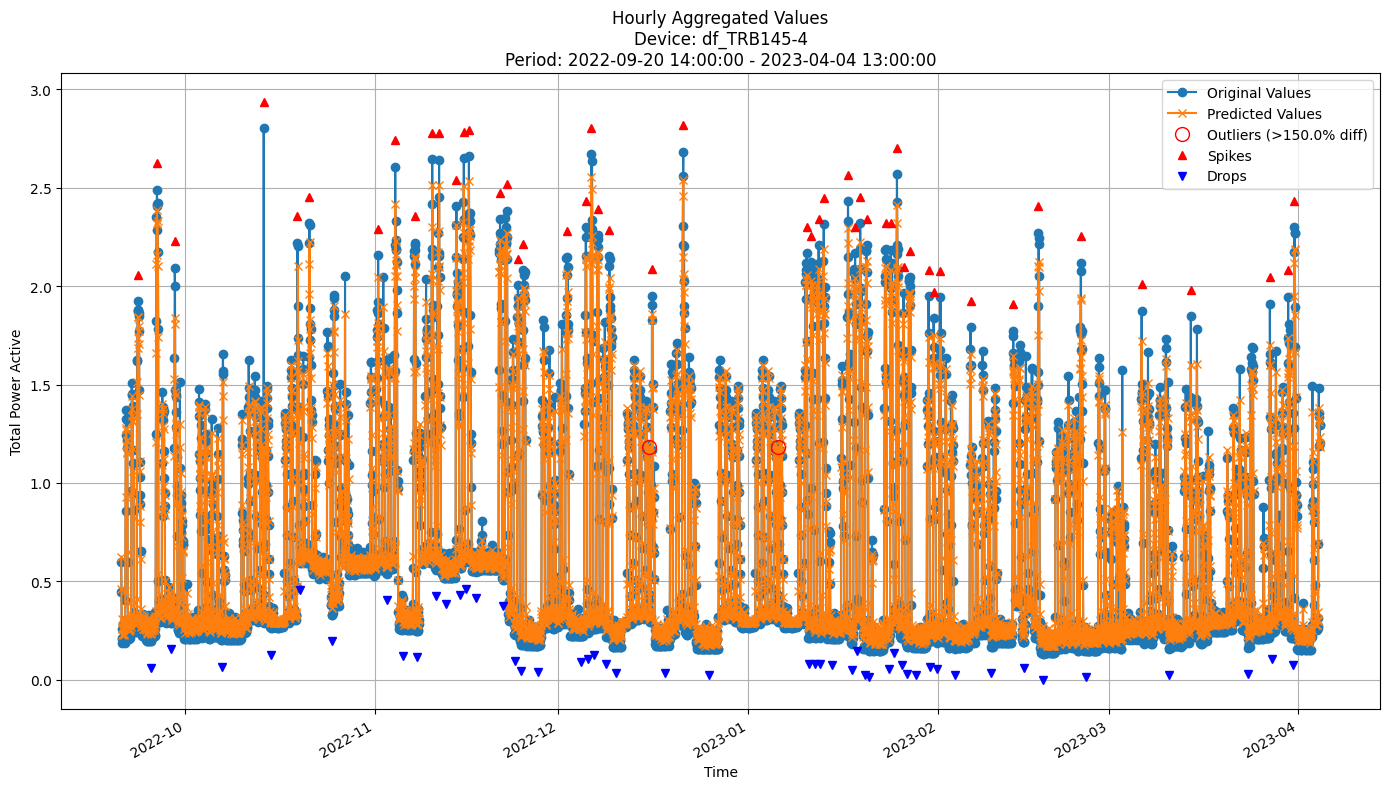


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0615
MAE: 0.0400
MAPE: 9.4135%

Directional Metrics:
Directional Accuracy: 86.4980%
First-Diff Correlation: 0.9618

Immediate Detection (delta=0):
Spikes:
  Precision: 0.6842
  Recall: 0.7800
  F1 Score: 0.7290
Drops:
  Precision: 0.1964
  Recall: 0.2245
  F1 Score: 0.2095

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7895
  Recall: 0.9000
  F1 Score: 0.8411
Drops:
  Precision: 0.1964
  Recall: 0.2245
  F1 Score: 0.2095


In [19]:
for device_id in gbdt_train_period_predictions.keys():
    y_train = gbdt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = gbdt_train_period_predictions[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)
# 0.17, 0.12, 25.55, 70.81%, 0.72

#### Validation plots
Plot only the last few periods of predictions

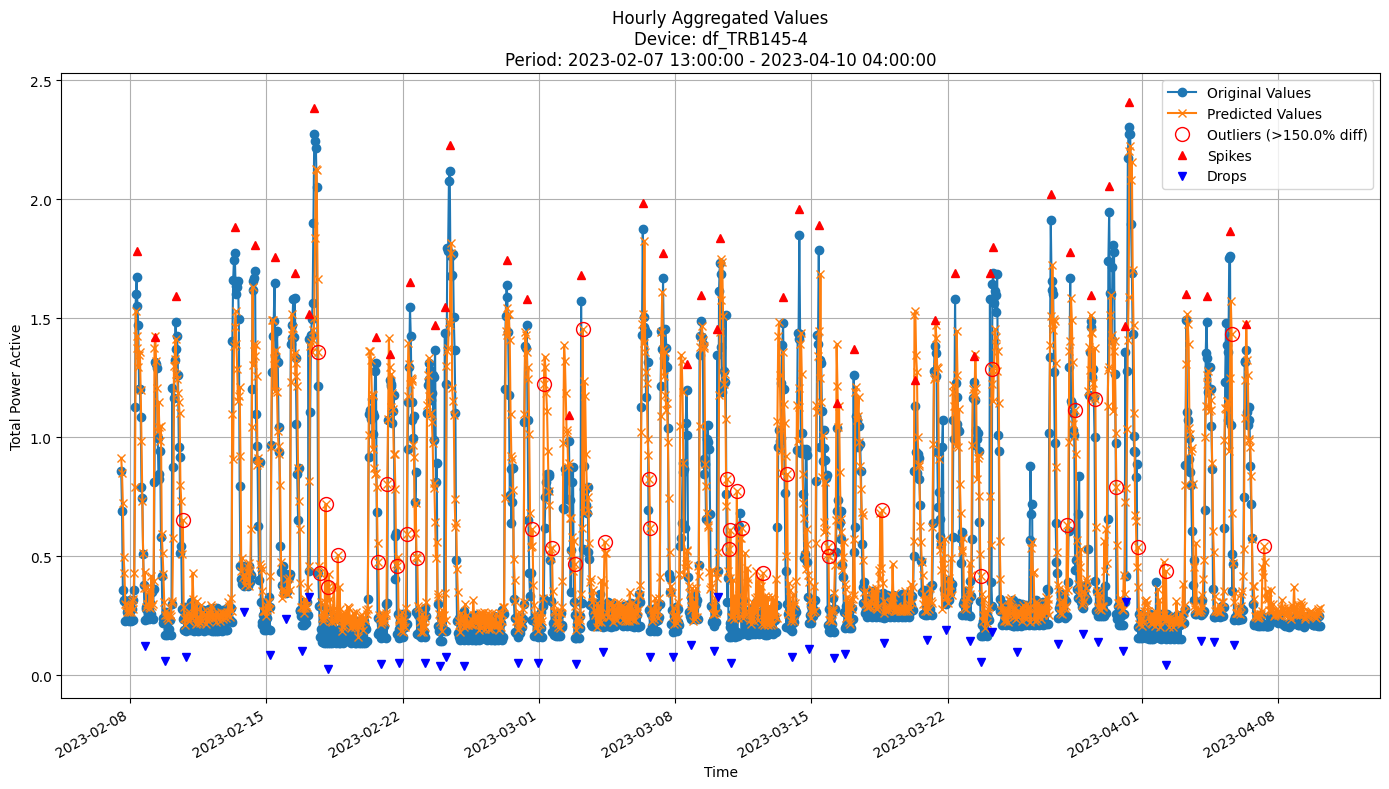


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2173
MAE: 0.1379
MAPE: 33.1960%

Directional Metrics:
Directional Accuracy: 59.5399%
First-Diff Correlation: 0.3715

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1220
  Recall: 0.1087
  F1 Score: 0.1149
Drops:
  Precision: 0.1500
  Recall: 0.1333
  F1 Score: 0.1412

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.4146
  Recall: 0.3696
  F1 Score: 0.3908
Drops:
  Precision: 0.2250
  Recall: 0.2000
  F1 Score: 0.2118


In [20]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in gbdt_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, gbdt_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, gbdt_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

# Basic Prediction Metrics:
# RMSE: 0.2195
# MAE: 0.1398
# MAPE: 33.6987%

### Random Forest model

In [21]:
update_freq = "14D"  # Update the model every 14 days
rf = RandomForestRegressor
rf_params = dict(n_estimators=100, max_depth=10, max_features='sqrt', random_state=42, n_jobs=-1)

In [22]:

rf_train_period_predictions, rf_valid_period_predictions, \
rf_train_period_metrics, rf_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=rf, 
    model_params=rf_params, 
    train=train, 
    valid=valid, 
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 14:00:00+02:00 to 2022-10-18 13:00:00+02:00

Time: 0.12 seconds
Predicting for chunk from 2022-10-18 14:00:00+02:00 to 2022-11-01 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-20 14:00:00+02:00 to 2022-11-01 13:00:00+01:00

Time: 0.12 seconds
Predicting for chunk from 2022-11-01 14:00:00+01:00 to 2022-11-15 12:00:00+01:00

-------------------------
Model's memory usage: 0.042160 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-18 14:00:00+02:00 - 2022-11-15 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2970
	MAE: 0.1870
	MAPE: 20.9066%

Directional Metrics:
	Directional Accuracy: 59.1654%
	First-Diff Correlation: 0.3264

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.5000
		Recall: 0.1538
		F1: 0.2353

Delayed Detection (

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 14:00:00+02:00 to 2022-11-15 12:00:00+01:00

Time: 0.12 seconds
Predicting for chunk from 2022-11-15 13:00:00+01:00 to 2022-11-29 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-20 14:00:00+02:00 to 2022-11-29 13:00:00+01:00

Time: 0.12 seconds
Predicting for chunk from 2022-11-29 14:00:00+01:00 to 2022-12-13 12:00:00+01:00

-------------------------
Model's memory usage: 0.042152 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 13:00:00+01:00 - 2022-12-13 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2724
	MAE: 0.1704
	MAPE: 30.1619%

Directional Metrics:
	Directional Accuracy: 57.9732%
	First-Diff Correlation: 0.4298

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 14:00:00+02:00 to 2023-03-07 12:00:00+01:00

Time: 0.24 seconds
Predicting for chunk from 2023-03-07 13:00:00+01:00 to 2023-03-21 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-20 14:00:00+02:00 to 2023-03-21 13:00:00+01:00

Time: 0.21 seconds
Predicting for chunk from 2023-03-21 14:00:00+01:00 to 2023-04-04 13:00:00+02:00

-------------------------
Model's memory usage: 0.042152 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-07 13:00:00+01:00 - 2023-04-04 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2355
	MAE: 0.1557
	MAPE: 35.0947%

Directional Metrics:
	Directional Accuracy: 54.0984%
	First-Diff Correlation: 0.3051

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 14:00:00+02:00 to 2023-04-04 13:00:00+02:00

Time: 0.22 seconds
Predicting for chunk from 2023-04-04 14:00:00+02:00 to 2023-04-10 04:00:00+02:00

-------------------------
Model's memory usage: 0.042152 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-04 14:00:00+02:00 - 2023-04-10 04:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1601
	MAE: 0.0901
	MAPE: 25.4600%

Directional Metrics:
	Directional Accuracy: 55.2239%
	First-Diff Correlation: 0.3057

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.5000
		Recall: 0.3333
		F1: 0.4000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.6667
		F1: 0.8000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
------------------------------------------

#### Results

In [23]:
print("\n\nTrain period metrics:")
rf_all_time_train_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
rf_all_time_valid_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)

# Best values:
# Hourly Metrics:
# 	RMSE: 0.2221 ± 0.0148
# 	MAE: 0.1267 ± 0.0092
# 	MAPE: 22.1472% ± 2.0063%

# 	Directional Metrics:
# 		Directional Accuracy: 60.8511% ± 2.9815%
# 		First-Diff Correlation: 0.4859 ± 0.0565

# 	Immediate Detection (delta=0):
# 		Spike Precision: 0.2094 ± 0.0638
# 		Spike Recall: 0.1844 ± 0.0780
# 		Spike F1: 0.1927 ± 0.0741
# 		Drop Precision: 0.0547 ± 0.0125
# 		Drop Recall: 0.1408 ± 0.0536
# 		Drop F1: 0.0779 ± 0.0216

# 	1-Hour Delayed Detection (delta=1):
# 		Spike Precision: 0.4647 ± 0.0473
# 		Spike Recall: 0.3984 ± 0.1023
# 		Spike F1: 0.4191 ± 0.0799
# 		Drop Precision: 0.1104 ± 0.0172
# 		Drop Recall: 0.2821 ± 0.0884
# 		Drop F1: 0.1571 ± 0.0324



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.1121 ± 0.0112
	MAE: 0.0655 ± 0.0065
	MAPE: 11.9502% ± 1.4497%

	Directional Metrics:
		Directional Accuracy: 78.3085% ± 1.3684%
		First-Diff Correlation: 0.8770 ± 0.0316

	Immediate Detection (delta=0):
		Spike Precision: 0.3772 ± 0.3631
		Spike Recall: 0.1658 ± 0.1738
		Spike F1: 0.2051 ± 0.1903
		Drop Precision: 0.0734 ± 0.0882
		Drop Recall: 0.0497 ± 0.0725
		Drop F1: 0.0562 ± 0.0746

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4722 ± 0.4170
		Spike Recall: 0.2339 ± 0.2672
		Spike F1: 0.2816 ± 0.2834
		Drop Precision: 0.0884 ± 0.1151
		Drop Recall: 0.0647 ± 0.1070
		Drop F1: 0.0712 ± 0.1076
Daily Metrics:
	RMSE: 0.8323 ± 0.1132
	MAE: 0.6212 ± 0.0741
	MAPE: 4.4301% ± 0.3428%

	Directional Metrics:
		Directional Accuracy: 92.5705% ± 2.5257%
		First-Diff Correlation: 0.9949 ± 0.0015

	Immediate Detection (delta=0):


#### Training plots
Plot only the last period of predictions

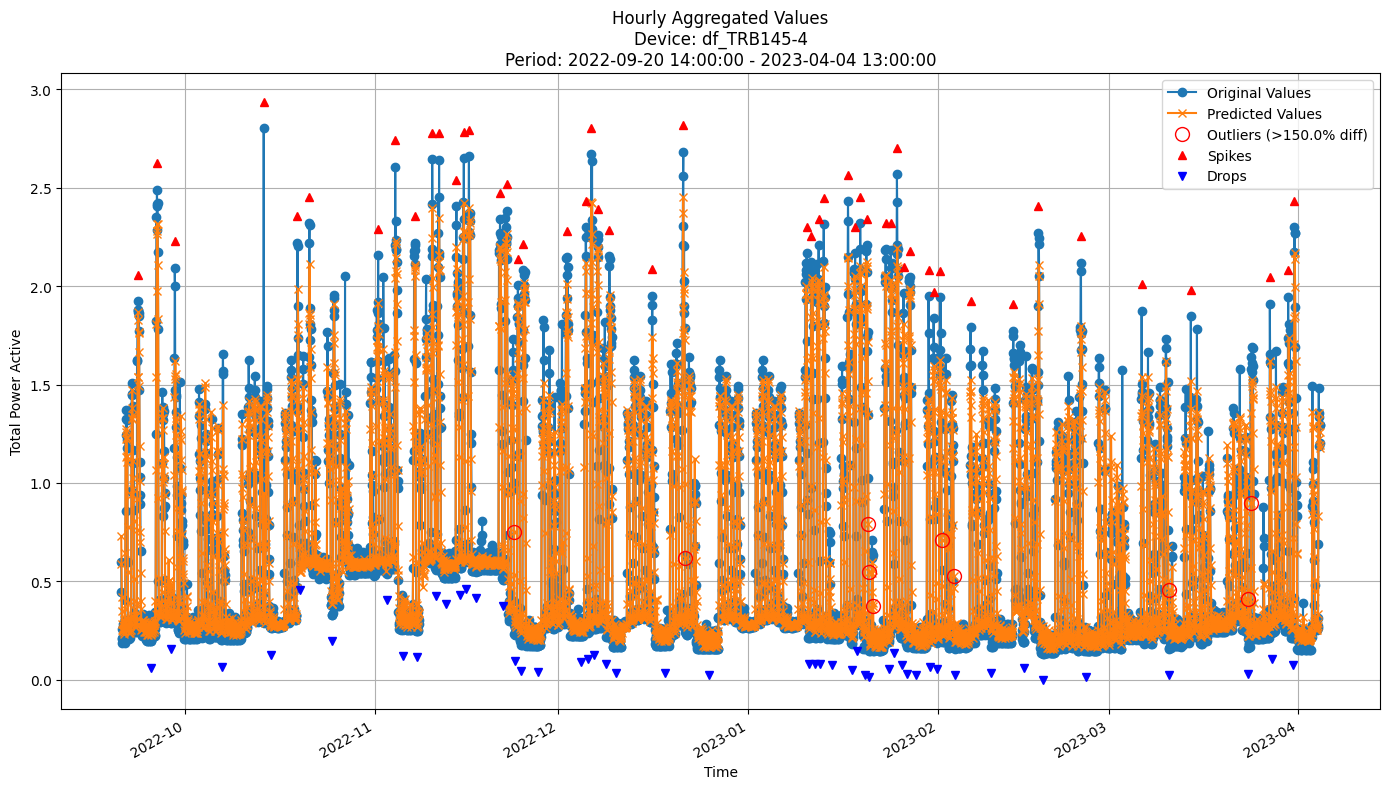


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1286
MAE: 0.0756
MAPE: 14.7259%

Directional Metrics:
Directional Accuracy: 75.5688%
First-Diff Correlation: 0.8296

Immediate Detection (delta=0):
Spikes:
  Precision: 0.5000
  Recall: 0.3400
  F1 Score: 0.4048
Drops:
  Precision: 0.1212
  Recall: 0.0816
  F1 Score: 0.0976

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7353
  Recall: 0.5000
  F1 Score: 0.5952
Drops:
  Precision: 0.1212
  Recall: 0.0816
  F1 Score: 0.0976


In [24]:
for device_id in rf_train_period_predictions.keys():
    y_train = rf_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = rf_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last periods of predictions

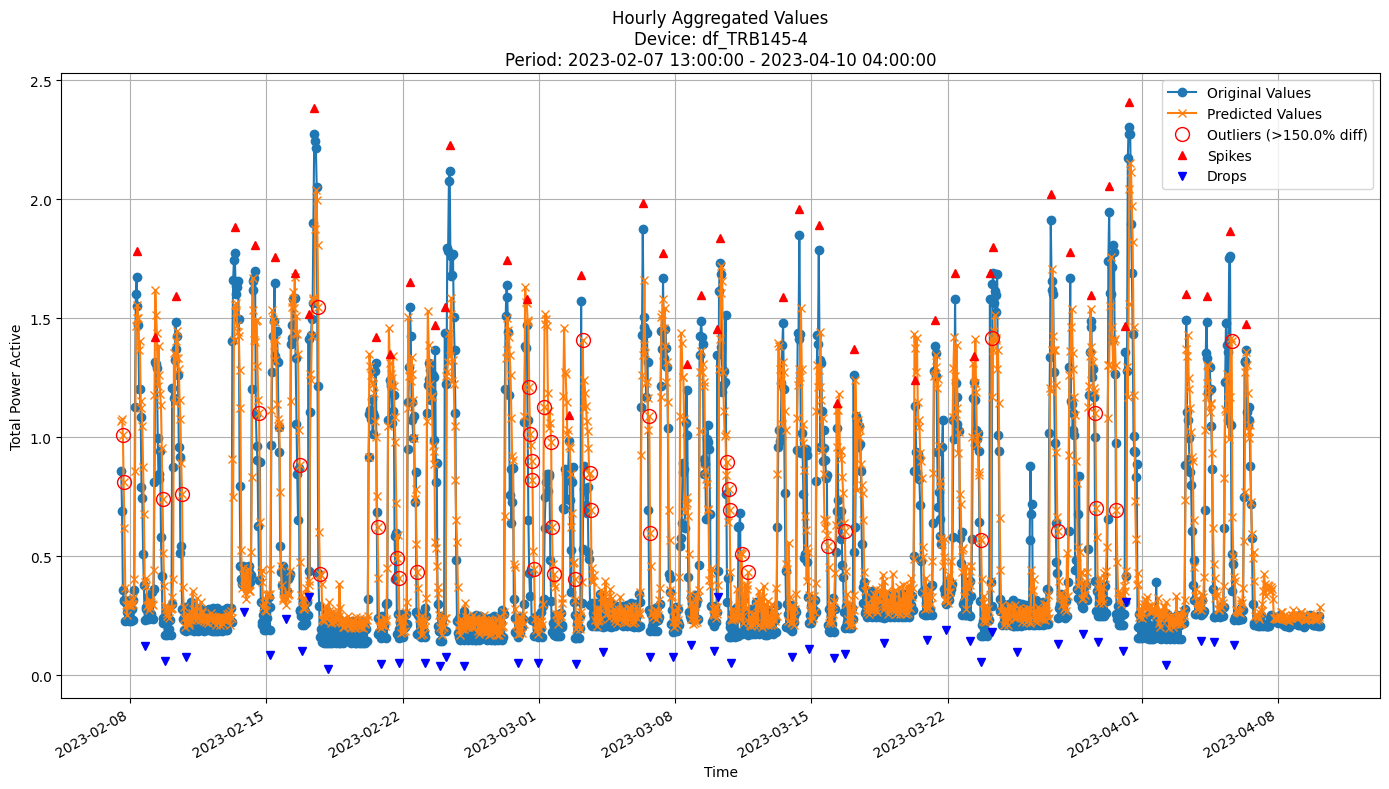


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2338
MAE: 0.1465
MAPE: 34.3431%

Directional Metrics:
Directional Accuracy: 60.2842%
First-Diff Correlation: 0.4027

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1282
  Recall: 0.1087
  F1 Score: 0.1176
Drops:
  Precision: 0.1579
  Recall: 0.1333
  F1 Score: 0.1446

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3333
  Recall: 0.2826
  F1 Score: 0.3059
Drops:
  Precision: 0.2105
  Recall: 0.1778
  F1 Score: 0.1928


In [25]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in rf_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, rf_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, rf_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Hoeffding Tree

In [26]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

hoef = HoeffdingTreeRegressor
hoef_params = dict(max_depth=10, grace_period=10, delta=0.5, tau=0.05, leaf_prediction="mean")


In [27]:

hoef_all_train_preds, hoef_all_valid_preds, \
hoef_all_train_metrics, hoef_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=hoef, 
    model_params=hoef_params, 
    train=train, 
    valid=valid, 
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 14:00:00+02:00 to 2022-10-18 13:00:00+02:00
Model's memory usage: 1.923264 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-18 14:00:00+02:00 - 2022-11-15 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3800
	MAE: 0.2604
	MAPE: 29.1587%

Directional Metrics:
	Directional Accuracy: 44.7094%
	First-Diff Correlation: 0.1985

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
----------------------------------------------

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 14:00:00+02:00 to 2022-11-15 12:00:00+01:00
Model's memory usage: 3.191780 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 13:00:00+01:00 - 2022-12-13 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3900
	MAE: 0.2493
	MAPE: 40.9155%

Directional Metrics:
	Directional Accuracy: 52.7571%
	First-Diff Correlation: 0.2019

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
----------------------------------------------

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 14:00:00+02:00 to 2023-03-07 12:00:00+01:00
Model's memory usage: 5.588203 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-07 13:00:00+01:00 - 2023-04-04 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3031
	MAE: 0.1969
	MAPE: 42.0215%

Directional Metrics:
	Directional Accuracy: 49.1803%
	First-Diff Correlation: 0.2188

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1429
		Recall: 0.1053
		F1: 0.1212
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.3571
		Recall: 0.2632
		F1: 0.3030
	Drops:
		Precision: 0.0714
		Recall: 0.0500
		F1: 0.0588
----------------------------------------------

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 14:00:00+02:00 to 2023-04-04 13:00:00+02:00
Model's memory usage: 5.735168 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-04 14:00:00+02:00 - 2023-04-10 04:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2478
	MAE: 0.1389
	MAPE: 44.3894%

Directional Metrics:
	Directional Accuracy: 47.0149%
	First-Diff Correlation: 0.3982

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.3333
		Recall: 0.3333
		F1: 0.3333
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
----------------------------------------------

#### Results

In [28]:
print("\n\nTrain period metrics:")
hoef_all_time_train_metrics = all_time_aggregation_metrics(hoef_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
hoef_all_time_valid_metrics = all_time_aggregation_metrics(hoef_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.3209 ± 0.0196
	MAE: 0.2010 ± 0.0200
	MAPE: 35.3502% ± 3.4630%

	Directional Metrics:
		Directional Accuracy: 33.0668% ± 4.6346%
		First-Diff Correlation: 0.2528 ± 0.0632

	Immediate Detection (delta=0):
		Spike Precision: 0.0511 ± 0.0628
		Spike Recall: 0.0674 ± 0.0858
		Spike F1: 0.0580 ± 0.0724
		Drop Precision: 0.0159 ± 0.0193
		Drop Recall: 0.0369 ± 0.0466
		Drop F1: 0.0222 ± 0.0272

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.1384 ± 0.1722
		Spike Recall: 0.1803 ± 0.2312
		Spike F1: 0.1562 ± 0.1968
		Drop Precision: 0.0448 ± 0.0649
		Drop Recall: 0.0958 ± 0.1295
		Drop F1: 0.0609 ± 0.0863
Daily Metrics:
	RMSE: 3.4487 ± 0.2896
	MAE: 2.7102 ± 0.3453
	MAPE: 20.5485% ± 3.4257%

	Directional Metrics:
		Directional Accuracy: 77.3591% ± 2.7067%
		First-Diff Correlation: 0.8936 ± 0.0368

	Immediate Detection (delta=0):

#### Training plots
Plot only the last period of predictions

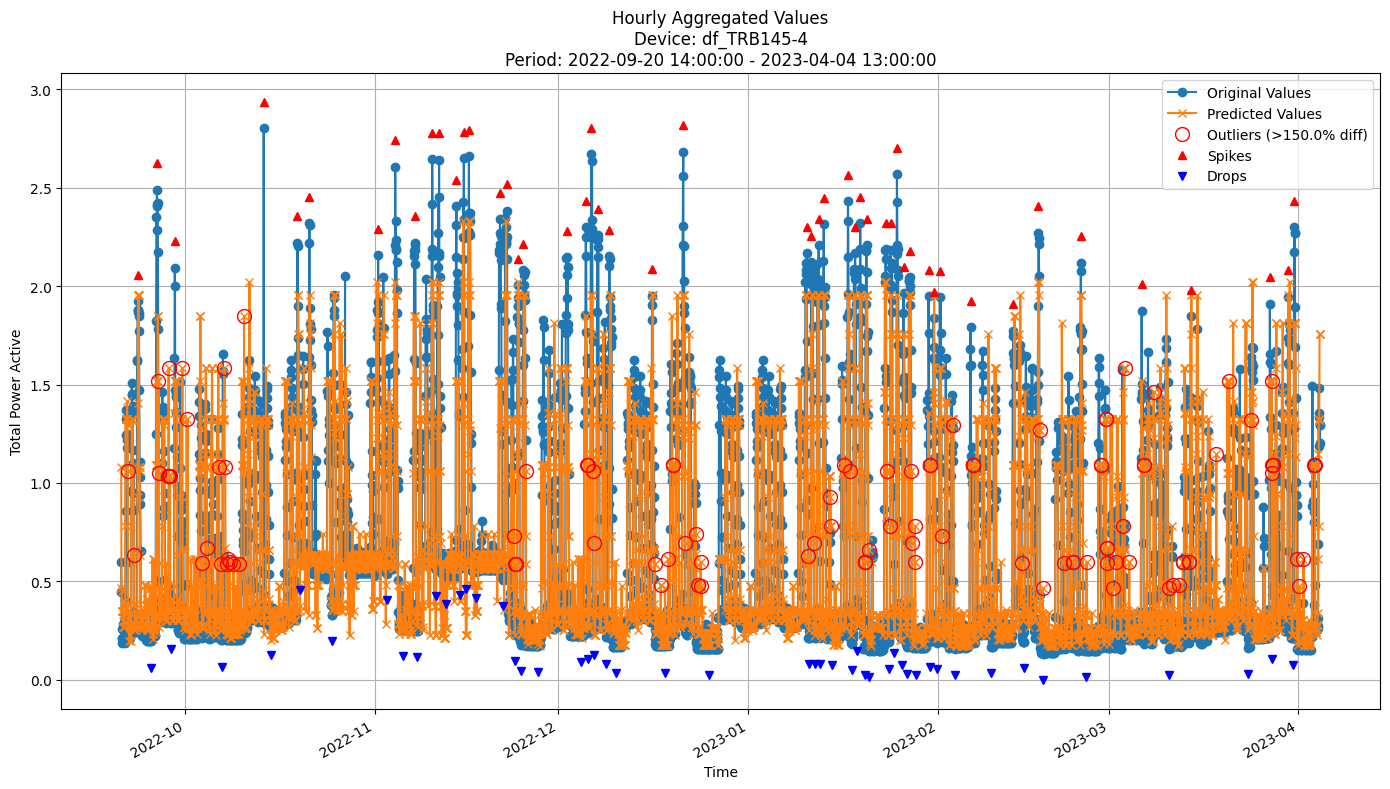


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2958
MAE: 0.1800
MAPE: 32.5266%

Directional Metrics:
Directional Accuracy: 38.2522%
First-Diff Correlation: 0.2955

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1286
  Recall: 0.1800
  F1 Score: 0.1500
Drops:
  Precision: 0.0488
  Recall: 0.1224
  F1 Score: 0.0698

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2571
  Recall: 0.3600
  F1 Score: 0.3000
Drops:
  Precision: 0.0650
  Recall: 0.1633
  F1 Score: 0.0930


In [29]:
for device_id in hoef_all_train_preds.keys():
    y_train = hoef_all_train_preds[device_id][-1]['y_true']
    y_pred_train = hoef_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

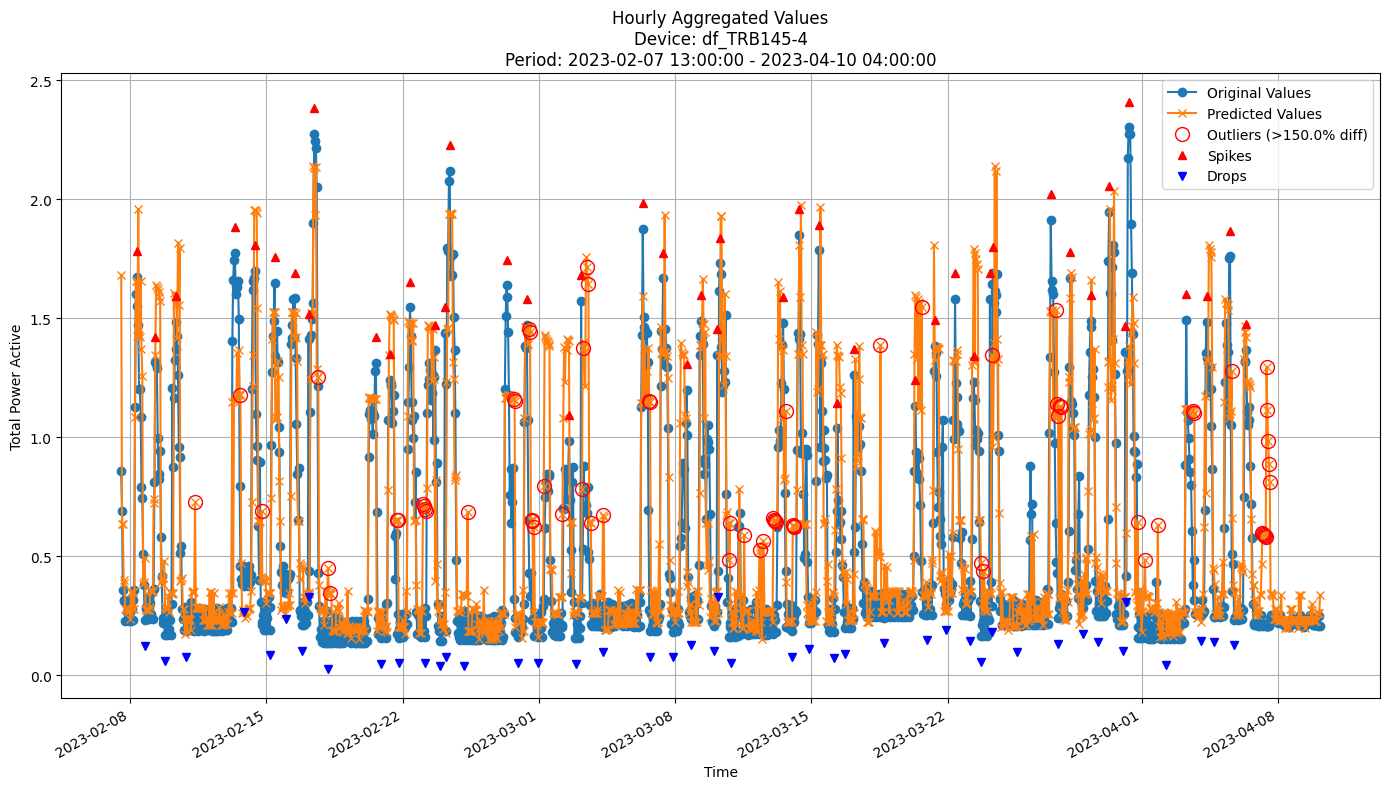


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2892
MAE: 0.1814
MAPE: 41.9351%

Directional Metrics:
Directional Accuracy: 49.9323%
First-Diff Correlation: 0.3129

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1351
  Recall: 0.1087
  F1 Score: 0.1205
Drops:
  Precision: 0.0811
  Recall: 0.0667
  F1 Score: 0.0732

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3514
  Recall: 0.2826
  F1 Score: 0.3133
Drops:
  Precision: 0.1892
  Recall: 0.1556
  F1 Score: 0.1707


In [30]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in hoef_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, hoef_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, hoef_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (Hoeffding Tree)

In [31]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

arf_hf = ARFRegressor
arf_hf_params = dict(n_models=10, 
                     max_features=0.8, 
                     aggregation_method='median', 
                     grace_period=10, 
                     max_depth=10, 
                     delta=0.5, 
                     tau=0.01, 
                     seed=42)


In [32]:
arf_hf_all_train_preds, arf_hf_all_valid_preds, \
arf_hf_all_train_metrics, arf_hf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf_hf,
    model_params=arf_hf_params,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 14:00:00+02:00 to 2022-10-18 13:00:00+02:00
Model's memory usage: 9.019135 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-18 14:00:00+02:00 - 2022-11-15 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3464
	MAE: 0.2316
	MAPE: 27.9152%

Directional Metrics:
	Directional Accuracy: 54.0984%
	First-Diff Correlation: 0.3346

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.2500
		Recall: 0.0769
		F1: 0.1176
----------------------------------------------

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 14:00:00+02:00 to 2022-11-15 12:00:00+01:00
Model's memory usage: 14.511780 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 13:00:00+01:00 - 2022-12-13 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3151
	MAE: 0.2317
	MAPE: 52.0286%

Directional Metrics:
	Directional Accuracy: 59.7615%
	First-Diff Correlation: 0.4042

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
---------------------------------------------

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 14:00:00+02:00 to 2023-03-07 12:00:00+01:00
Model's memory usage: 26.991066 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-07 13:00:00+01:00 - 2023-04-04 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2540
	MAE: 0.1720
	MAPE: 38.6298%

Directional Metrics:
	Directional Accuracy: 54.2474%
	First-Diff Correlation: 0.3411

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2000
		Recall: 0.1579
		F1: 0.1765
	Drops:
		Precision: 0.1875
		Recall: 0.1500
		F1: 0.1667

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.3333
		Recall: 0.2632
		F1: 0.2941
	Drops:
		Precision: 0.3125
		Recall: 0.2500
		F1: 0.2778
---------------------------------------------

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 14:00:00+02:00 to 2023-04-04 13:00:00+02:00
Model's memory usage: 27.680946 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-04 14:00:00+02:00 - 2023-04-10 04:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1784
	MAE: 0.1185
	MAPE: 39.7293%

Directional Metrics:
	Directional Accuracy: 52.9851%
	First-Diff Correlation: 0.5774

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.3333
		Recall: 0.3333
		F1: 0.3333
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.3333
		Recall: 0.3333
		F1: 0.3333
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
---------------------------------------------

#### Results

In [33]:
print("\n\nTrain period metrics:")
arf_hf_all_time_train_metrics = all_time_aggregation_metrics(arf_hf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_hf_all_time_valid_metrics = all_time_aggregation_metrics(arf_hf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.3016 ± 0.0373
	MAE: 0.2051 ± 0.0392
	MAPE: 41.7533% ± 11.8980%

	Directional Metrics:
		Directional Accuracy: 54.0921% ± 6.6064%
		First-Diff Correlation: 0.4406 ± 0.0915

	Immediate Detection (delta=0):
		Spike Precision: 0.0110 ± 0.0269
		Spike Recall: 0.0057 ± 0.0140
		Spike F1: 0.0075 ± 0.0184
		Drop Precision: 0.0417 ± 0.0569
		Drop Recall: 0.0202 ± 0.0251
		Drop F1: 0.0239 ± 0.0298

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.1558 ± 0.1854
		Spike Recall: 0.1143 ± 0.1964
		Spike F1: 0.1127 ± 0.1616
		Drop Precision: 0.0629 ± 0.0849
		Drop Recall: 0.0365 ± 0.0500
		Drop F1: 0.0412 ± 0.0568
Daily Metrics:
	RMSE: 4.2117 ± 0.7576
	MAE: 3.3662 ± 0.6868
	MAPE: 29.2438% ± 9.5060%

	Directional Metrics:
		Directional Accuracy: 72.7587% ± 7.2080%
		First-Diff Correlation: 0.8617 ± 0.0962

	Immediate Detection (delta=0)

#### Training plots

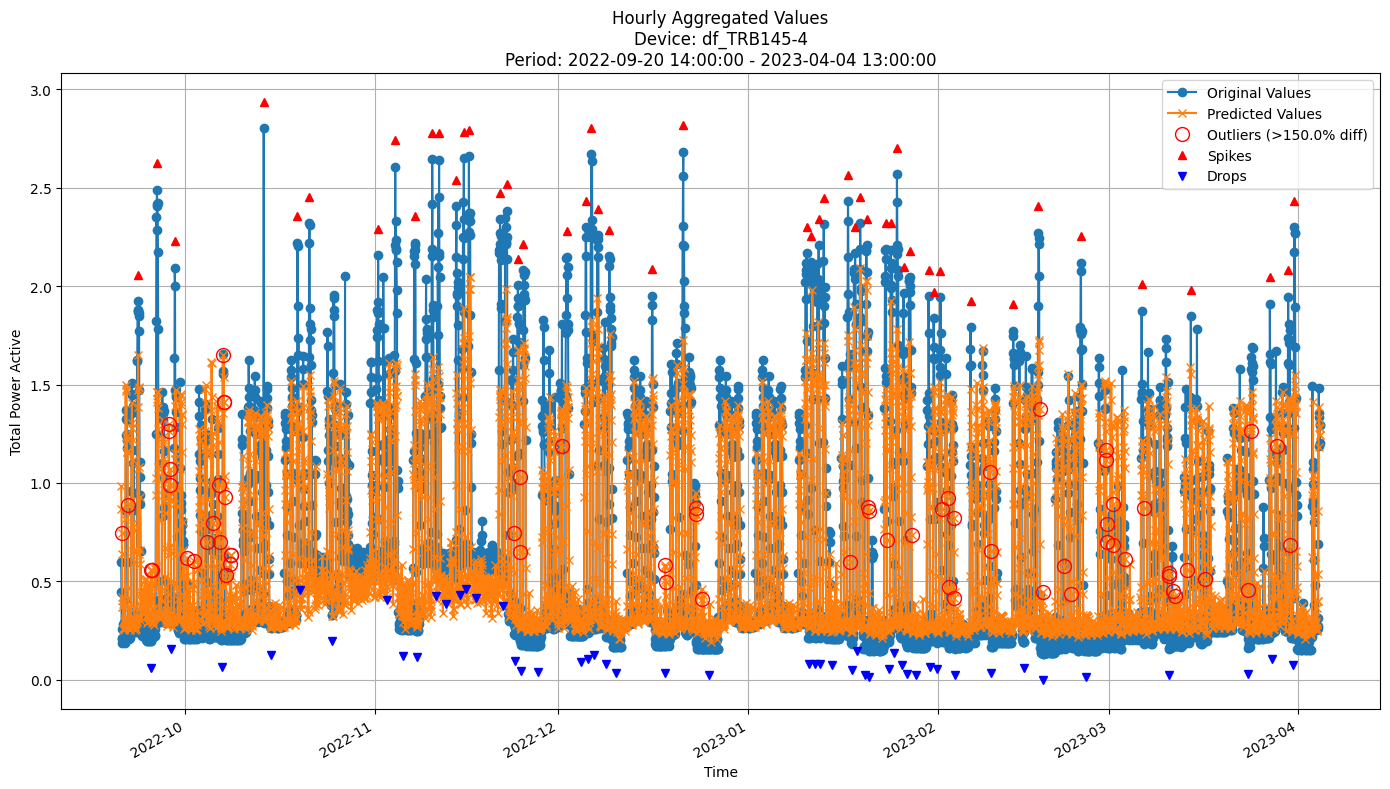


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2676
MAE: 0.1699
MAPE: 31.3256%

Directional Metrics:
Directional Accuracy: 58.8348%
First-Diff Correlation: 0.5138

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0769
  Recall: 0.0400
  F1 Score: 0.0526
Drops:
  Precision: 0.1154
  Recall: 0.0612
  F1 Score: 0.0800

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2692
  Recall: 0.1400
  F1 Score: 0.1842
Drops:
  Precision: 0.2308
  Recall: 0.1224
  F1 Score: 0.1600


In [34]:
for device_id in arf_hf_all_train_preds.keys():
    y_train = arf_hf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_hf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

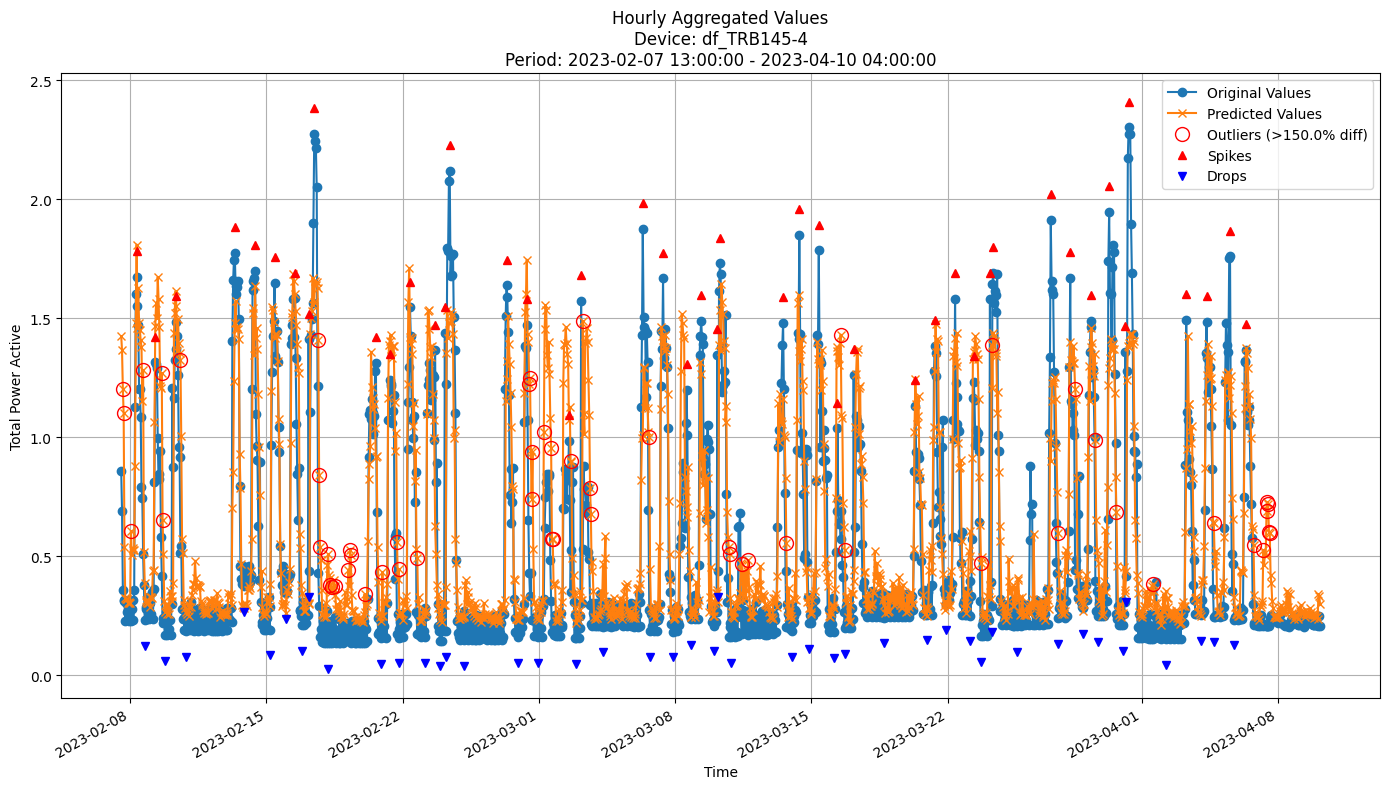


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2597
MAE: 0.1731
MAPE: 42.8735%

Directional Metrics:
Directional Accuracy: 55.8187%
First-Diff Correlation: 0.4172

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2195
  Recall: 0.1957
  F1 Score: 0.2069
Drops:
  Precision: 0.1951
  Recall: 0.1778
  F1 Score: 0.1860

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3659
  Recall: 0.3261
  F1 Score: 0.3448
Drops:
  Precision: 0.2927
  Recall: 0.2667
  F1 Score: 0.2791


In [35]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_hf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_hf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_hf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### FastODT

In [36]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

fodt = fastodt.FastODT

fodt_params = {'depth': 50, 
               'grace_period': 24, 
               'grace_period_depth': 0, 
               'split_confidence': 0.005, 
               'max_feature': 0.3, 
               'tie_threshold': 0.05, 
               'bin_type': 'mean', 
               'split_criterion': 'vr_rel'}

In [37]:
fodt_all_train_preds, fodt_all_valid_preds, \
fodt_all_train_metrics, fodt_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=fodt, 
    model_params=fodt_params, 
    train=train, 
    valid=valid, 
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 14:00:00+02:00 to 2022-10-18 13:00:00+02:00
Model's memory usage: 1.805534 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-18 14:00:00+02:00 - 2022-11-15 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3555
	MAE: 0.2258
	MAPE: 27.0014%

Directional Metrics:
	Directional Accuracy: 45.4545%
	First-Diff Correlation: 0.1919

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
----------------------------------------------

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 14:00:00+02:00 to 2022-11-15 12:00:00+01:00
Model's memory usage: 1.058655 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 13:00:00+01:00 - 2022-12-13 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3707
	MAE: 0.2097
	MAPE: 34.4676%

Directional Metrics:
	Directional Accuracy: 42.1759%
	First-Diff Correlation: 0.2097

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
----------------------------------------------

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 14:00:00+02:00 to 2023-03-07 12:00:00+01:00
Model's memory usage: 7.883995 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-07 13:00:00+01:00 - 2023-04-04 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3458
	MAE: 0.2080
	MAPE: 41.5145%

Directional Metrics:
	Directional Accuracy: 49.0313%
	First-Diff Correlation: 0.1437

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0909
		Recall: 0.1579
		F1: 0.1154
	Drops:
		Precision: 0.1212
		Recall: 0.2000
		F1: 0.1509

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2424
		Recall: 0.4211
		F1: 0.3077
	Drops:
		Precision: 0.2424
		Recall: 0.4000
		F1: 0.3019
----------------------------------------------

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 14:00:00+02:00 to 2023-04-04 13:00:00+02:00
Model's memory usage: 11.649803 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-04 14:00:00+02:00 - 2023-04-10 04:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2251
	MAE: 0.1044
	MAPE: 21.0481%

Directional Metrics:
	Directional Accuracy: 50.7463%
	First-Diff Correlation: 0.2670

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.5000
		Recall: 0.6667
		F1: 0.5714
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.5000
		Recall: 0.6667
		F1: 0.5714
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
---------------------------------------------

#### Results

In [38]:
print("\n\nTrain period metrics:")
fodt_all_time_train_metrics = all_time_aggregation_metrics(fodt_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
fodt_all_time_valid_metrics = all_time_aggregation_metrics(fodt_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.4195 ± 0.0633
	MAE: 0.2523 ± 0.0463
	MAPE: 39.1582% ± 5.1514%

	Directional Metrics:
		Directional Accuracy: 34.4989% ± 11.3283%
		First-Diff Correlation: 0.2710 ± 0.0414

	Immediate Detection (delta=0):
		Spike Precision: 0.0568 ± 0.0684
		Spike Recall: 0.1261 ± 0.1199
		Spike F1: 0.0746 ± 0.0840
		Drop Precision: 0.0210 ± 0.0330
		Drop Recall: 0.0533 ± 0.0690
		Drop F1: 0.0293 ± 0.0447

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.1176 ± 0.1289
		Spike Recall: 0.3507 ± 0.2398
		Spike F1: 0.1591 ± 0.1623
		Drop Precision: 0.0408 ± 0.0560
		Drop Recall: 0.1296 ± 0.1395
		Drop F1: 0.0595 ± 0.0769
Daily Metrics:
	RMSE: 5.1227 ± 1.2612
	MAE: 3.7968 ± 1.0713
	MAPE: 24.6481% ± 6.6358%

	Directional Metrics:
		Directional Accuracy: 72.1538% ± 4.1952%
		First-Diff Correlation: 0.8077 ± 0.0604

	Immediate Detection (delta=0)

#### Training plots


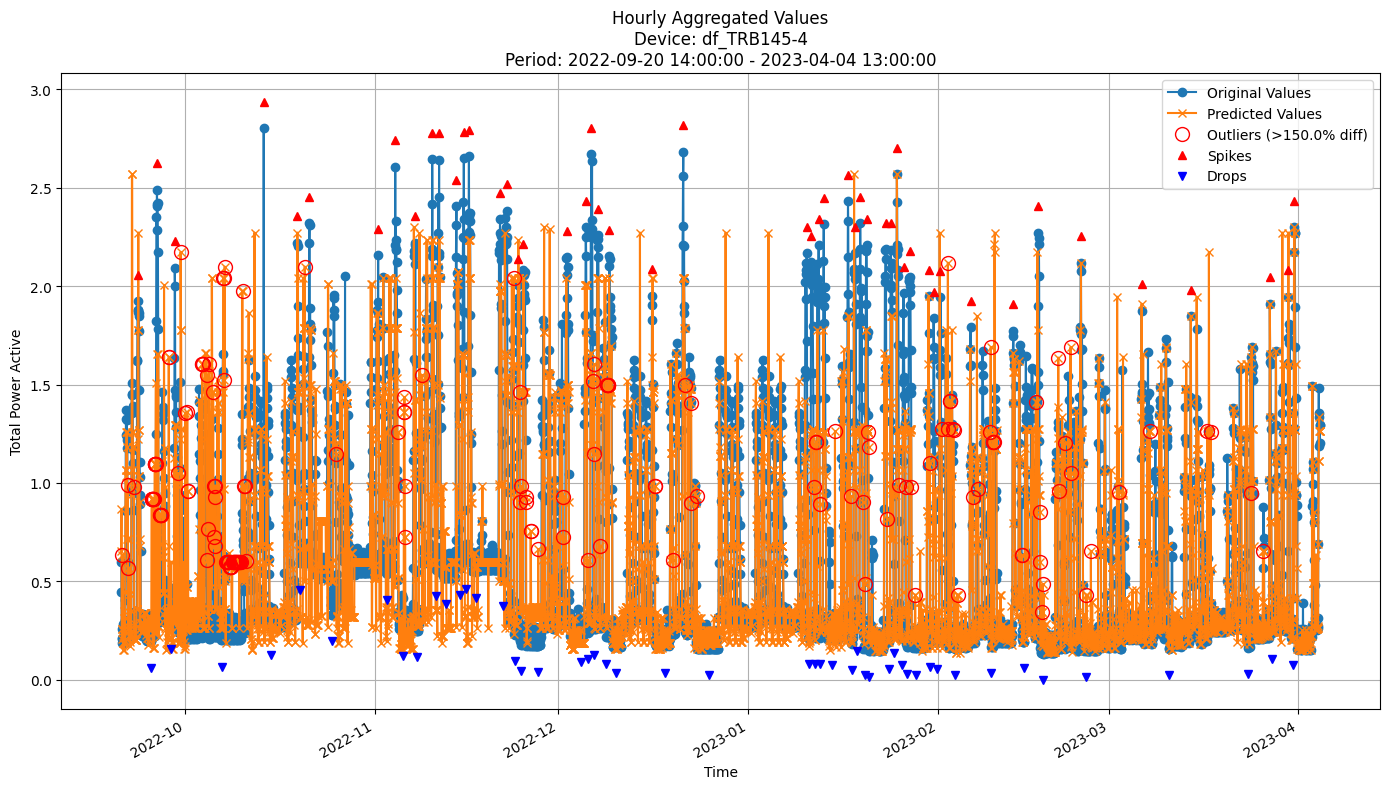


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3494
MAE: 0.2045
MAPE: 35.6778%

Directional Metrics:
Directional Accuracy: 41.0589%
First-Diff Correlation: 0.3218

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1618
  Recall: 0.2200
  F1 Score: 0.1864
Drops:
  Precision: 0.0319
  Recall: 0.0612
  F1 Score: 0.0420

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2647
  Recall: 0.3600
  F1 Score: 0.3051
Drops:
  Precision: 0.0319
  Recall: 0.0612
  F1 Score: 0.0420


In [39]:
for device_id in fodt_all_train_preds.keys():
    y_train = fodt_all_train_preds[device_id][-1]['y_true']
    y_pred_train = fodt_all_train_preds[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id,
                            spike_prominence=SPIKE_PROMINENCE, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

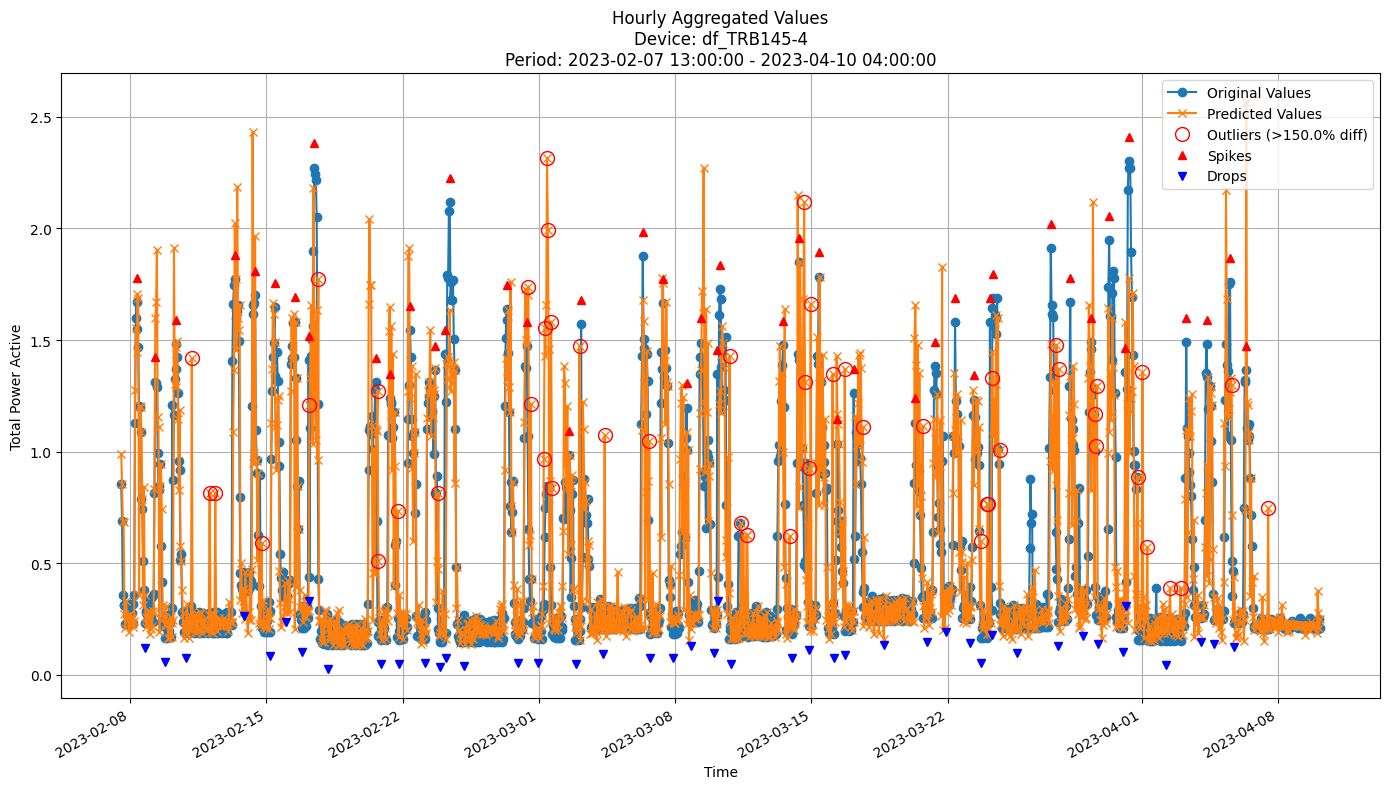


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3203
MAE: 0.1831
MAPE: 37.0201%

Directional Metrics:
Directional Accuracy: 51.9621%
First-Diff Correlation: 0.2130

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1389
  Recall: 0.2174
  F1 Score: 0.1695
Drops:
  Precision: 0.0822
  Recall: 0.1333
  F1 Score: 0.1017

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2917
  Recall: 0.4565
  F1 Score: 0.3559
Drops:
  Precision: 0.2192
  Recall: 0.3556
  F1 Score: 0.2712


In [40]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in fodt_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, fodt_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, fodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (FastODT)

In [41]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

arf = ARFRegressorFODT
arf_params = dict(n_models=20, 
                  aggregation_method="mean", 
                  grace_period=0,  # by default works for all leaves
                  disable_weighted_vote=True,
                  max_depth=50, 
                  delta=0.05, 
                  tau=0.01, 
                  seed=42, 
                  max_features=0.7, 
                  bin_type='mean', 
                  max_bins=1,
                  split_criterion='vr_rel',)


In [42]:

arf_all_train_preds, arf_all_valid_preds, \
arf_all_train_metrics, arf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf,
    model_params=arf_params,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 14:00:00+02:00 to 2022-10-18 13:00:00+02:00
Model's memory usage: 517.806732 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-18 14:00:00+02:00 - 2022-11-15 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3841
	MAE: 0.2670
	MAPE: 35.0301%

Directional Metrics:
	Directional Accuracy: 56.3338%
	First-Diff Correlation: 0.2292

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 14:00:00+02:00 to 2022-11-15 12:00:00+01:00
Model's memory usage: 181.094330 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 13:00:00+01:00 - 2022-12-13 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3824
	MAE: 0.2468
	MAPE: 46.9719%

Directional Metrics:
	Directional Accuracy: 53.5022%
	First-Diff Correlation: 0.3452

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 14:00:00+02:00 to 2023-03-07 12:00:00+01:00
Model's memory usage: 932.304855 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-07 13:00:00+01:00 - 2023-04-04 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2457
	MAE: 0.1544
	MAPE: 28.7992%

Directional Metrics:
	Directional Accuracy: 54.3964%
	First-Diff Correlation: 0.4633

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.3500
		Recall: 0.3684
		F1: 0.3590
	Drops:
		Precision: 0.1000
		Recall: 0.1000
		F1: 0.1000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6000
		Recall: 0.6316
		F1: 0.6154
	Drops:
		Precision: 0.2500
		Recall: 0.2500
		F1: 0.2500
--------------------------------------------

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 14:00:00+02:00 to 2023-04-04 13:00:00+02:00
Model's memory usage: 994.590164 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-04 14:00:00+02:00 - 2023-04-10 04:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2782
	MAE: 0.1479
	MAPE: 52.2810%

Directional Metrics:
	Directional Accuracy: 55.9701%
	First-Diff Correlation: 0.4925

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6667
		Recall: 0.6667
		F1: 0.6667
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------

#### Results

In [43]:
print("\n\nTrain period metrics:")
arf_all_time_train_metrics = all_time_aggregation_metrics(arf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_all_time_valid_metrics = all_time_aggregation_metrics(arf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.3715 ± 0.0424
	MAE: 0.2313 ± 0.0417
	MAPE: 37.2250% ± 11.2584%

	Directional Metrics:
		Directional Accuracy: 61.0885% ± 3.7449%
		First-Diff Correlation: 0.4671 ± 0.0756

	Immediate Detection (delta=0):
		Spike Precision: 0.0664 ± 0.1045
		Spike Recall: 0.1208 ± 0.1159
		Spike F1: 0.0781 ± 0.1036
		Drop Precision: 0.0192 ± 0.0336
		Drop Recall: 0.0349 ± 0.0414
		Drop F1: 0.0226 ± 0.0345

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.1484 ± 0.2074
		Spike Recall: 0.2948 ± 0.2610
		Spike F1: 0.1803 ± 0.2088
		Drop Precision: 0.0594 ± 0.0819
		Drop Recall: 0.1251 ± 0.1117
		Drop F1: 0.0737 ± 0.0847
Daily Metrics:
	RMSE: 5.7557 ± 0.9371
	MAE: 4.1454 ± 0.7571
	MAPE: 27.3035% ± 7.4507%

	Directional Metrics:
		Directional Accuracy: 67.5328% ± 3.3842%
		First-Diff Correlation: 0.7994 ± 0.0181

	Immediate Detection (delta=0)

#### Training plots

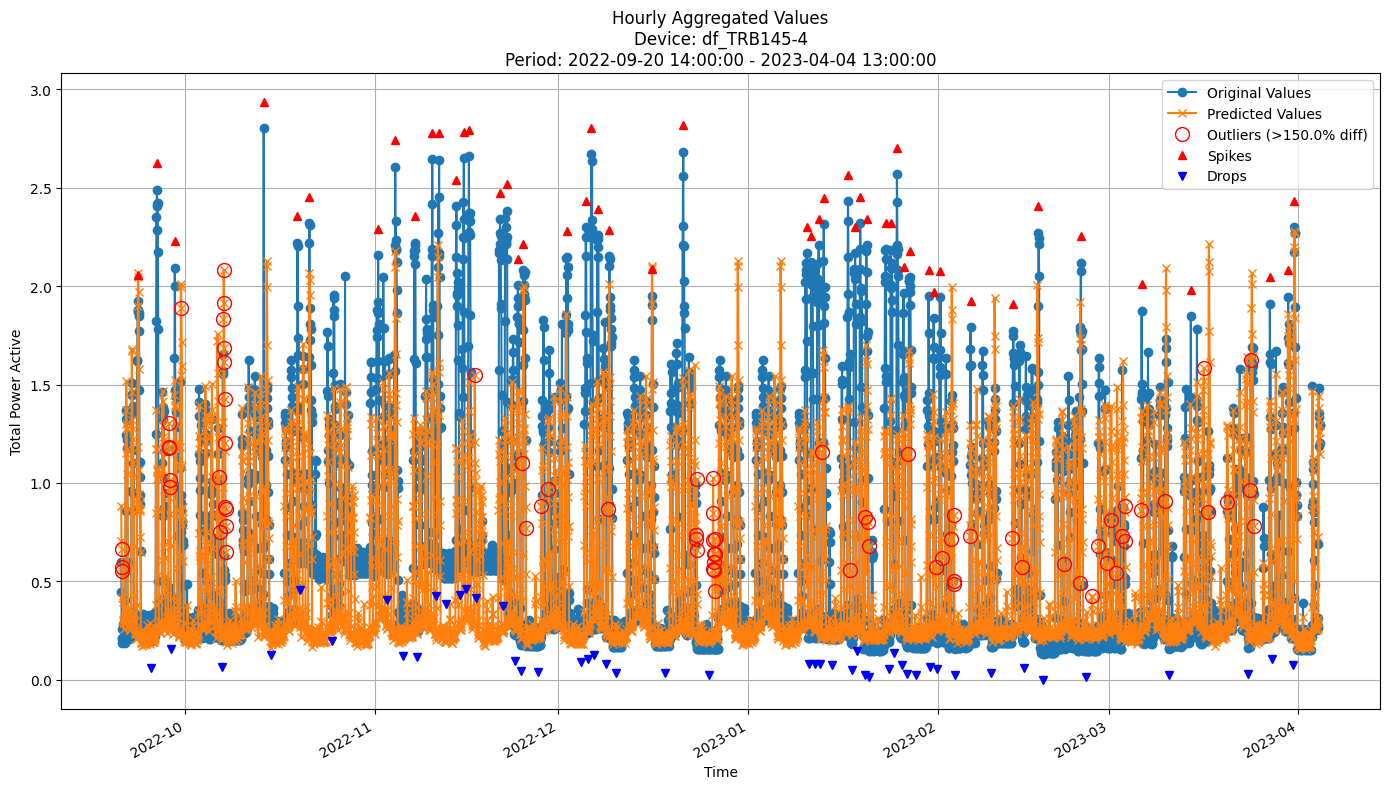


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3578
MAE: 0.2175
MAPE: 32.3130%

Directional Metrics:
Directional Accuracy: 60.9824%
First-Diff Correlation: 0.5153

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0507
  Recall: 0.1400
  F1 Score: 0.0745
Drops:
  Precision: 0.0072
  Recall: 0.0204
  F1 Score: 0.0107

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1594
  Recall: 0.4400
  F1 Score: 0.2340
Drops:
  Precision: 0.0580
  Recall: 0.1633
  F1 Score: 0.0856


In [44]:
for device_id in arf_all_train_preds.keys():
    y_train = arf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

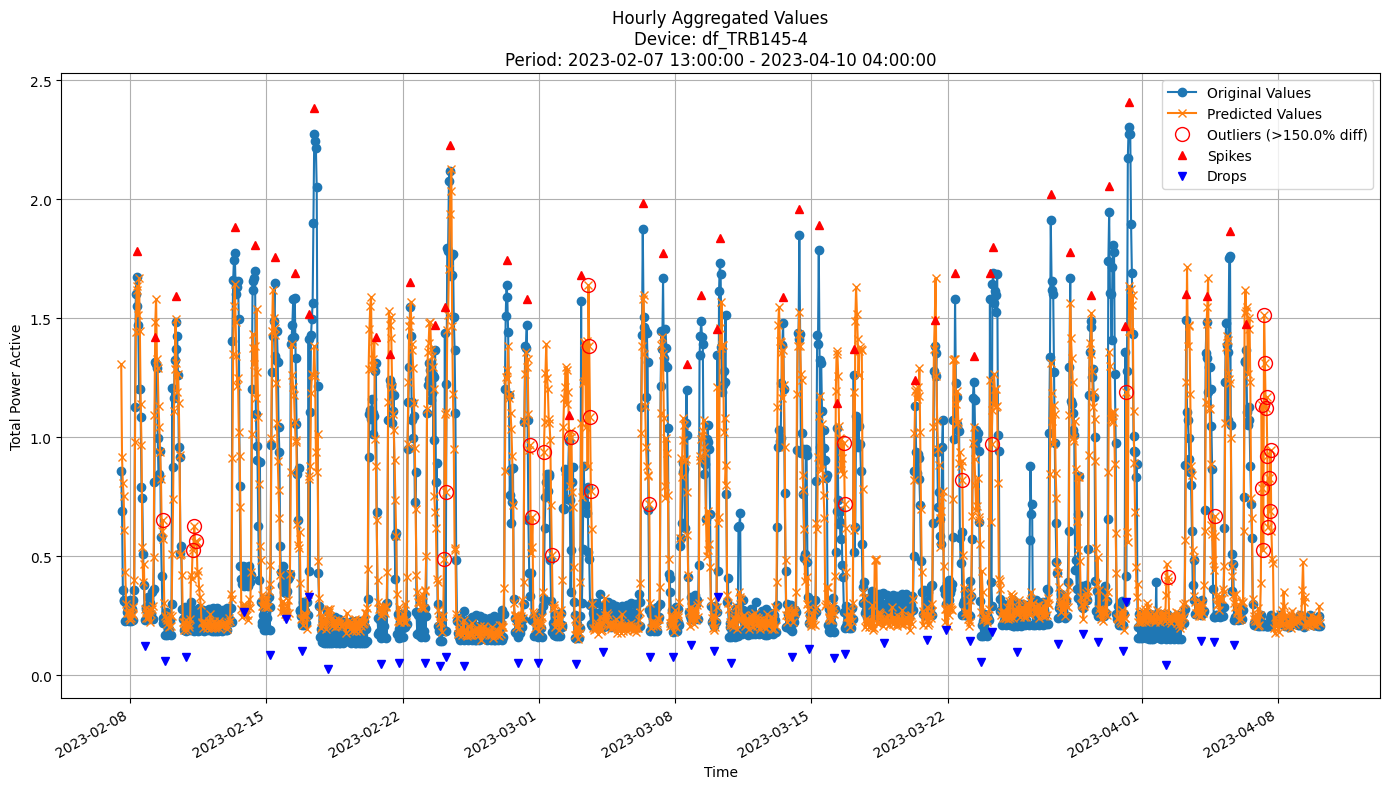


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2428
MAE: 0.1504
MAPE: 32.8429%

Directional Metrics:
Directional Accuracy: 55.3451%
First-Diff Correlation: 0.5101

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2326
  Recall: 0.2174
  F1 Score: 0.2247
Drops:
  Precision: 0.0698
  Recall: 0.0667
  F1 Score: 0.0682

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5349
  Recall: 0.5000
  F1 Score: 0.5169
Drops:
  Precision: 0.2558
  Recall: 0.2444
  F1 Score: 0.2500


In [45]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### iNcubation Boost

In [46]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario:

split_confidence_hf = 0.01
grace_period = 24
depth = 50
eagerness = 0
bin_type = 'mean'  # 'mean' or 'adaptive'
max_bins = 1
# max_bins = 32  # for adaptive binning
max_features = 0.7
tie_threshold = 0.05
grace_period_depth = -1 # set to 1 to use only for first node, set to -1 to use for all nodes, set to N to use for N nodes

incb = IncubationBoost
incb_params = dict(
    base_learner=fastodt.FastODT,
    length=20,
    learning_rate=0.5,
    depth=depth,
    grace_period=grace_period,
    split_confidence=split_confidence_hf,
    eagerness=eagerness,
    grace_period_depth=grace_period_depth,
    bin_type=bin_type,
    max_bins=max_bins,
    max_feature=max_features,
    tie_threshold=tie_threshold,
    split_criterion='vr_rel',
    verbose=False
)

In [47]:
incb_all_train_preds, incb_all_valid_preds, \
incb_all_train_metrics, incb_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=incb, 
    model_params=incb_params, 
    train=train, 
    valid=valid, 
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    # end_split=1,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 14:00:00+02:00 to 2022-10-18 13:00:00+02:00
Model's memory usage: 0.520950 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-18 14:00:00+02:00 - 2022-11-15 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.5925
	MAE: 0.4505
	MAPE: 47.1415%

Directional Metrics:
	Directional Accuracy: 41.1326%
	First-Diff Correlation: 0.1980

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1667
		Recall: 0.0769
		F1: 0.1053
	Drops:
		Precision: 0.1667
		Recall: 0.0769
		F1: 0.1053

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.1667
		Recall: 0.0769
		F1: 0.1053
	Drops:
		Precision: 0.3333
		Recall: 0.1538
		F1: 0.2105
----------------------------------------------

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 14:00:00+02:00 to 2022-11-15 12:00:00+01:00
Model's memory usage: 0.414917 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 13:00:00+01:00 - 2022-12-13 12:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.5762
	MAE: 0.3977
	MAPE: 46.7117%

Directional Metrics:
	Directional Accuracy: 43.6662%
	First-Diff Correlation: 0.3016

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
----------------------------------------------

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 14:00:00+02:00 to 2023-03-07 12:00:00+01:00
Model's memory usage: 1.777847 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-07 13:00:00+01:00 - 2023-04-04 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.4242
	MAE: 0.2870
	MAPE: 46.3878%

Directional Metrics:
	Directional Accuracy: 41.2817%
	First-Diff Correlation: 0.2655

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0588
		Recall: 0.0526
		F1: 0.0556
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.1765
		Recall: 0.1579
		F1: 0.1667
	Drops:
		Precision: 0.0556
		Recall: 0.0500
		F1: 0.0526
----------------------------------------------

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 14:00:00+02:00 to 2023-04-04 13:00:00+02:00
Model's memory usage: 1.209007 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-04 14:00:00+02:00 - 2023-04-10 04:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2834
	MAE: 0.1700
	MAPE: 38.8200%

Directional Metrics:
	Directional Accuracy: 53.7313%
	First-Diff Correlation: 0.3420

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.5000
		Recall: 0.3333
		F1: 0.4000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
----------------------------------------------

#### Results

In [48]:
print("\n\nTrain period metrics:")
incb_all_time_train_metrics = all_time_aggregation_metrics(incb_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
incb_all_time_valid_metrics = all_time_aggregation_metrics(incb_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)
# Hourly Metrics:
# 	RMSE: 0.4348 ± 0.1387
# 	MAE: 0.3140 ± 0.0869
# 	MAPE: 60.2407% ± 12.6513%
# 	Dir Accuracy: 57.2071% ± 2.1944%
# 	First-Diff Correlation: 0.3343 ± 0.0699



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.5351 ± 0.0573
	MAE: 0.3646 ± 0.0481
	MAPE: 47.6396% ± 6.3835%

	Directional Metrics:
		Directional Accuracy: 16.3561% ± 7.3315%
		First-Diff Correlation: 0.2413 ± 0.0453

	Immediate Detection (delta=0):
		Spike Precision: 0.0198 ± 0.0313
		Spike Recall: 0.0457 ± 0.0815
		Spike F1: 0.0268 ± 0.0445
		Drop Precision: 0.0064 ± 0.0143
		Drop Recall: 0.0307 ± 0.0672
		Drop F1: 0.0106 ± 0.0236

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0720 ± 0.1008
		Spike Recall: 0.1550 ± 0.2277
		Spike F1: 0.0946 ± 0.1329
		Drop Precision: 0.0524 ± 0.0849
		Drop Recall: 0.1382 ± 0.1620
		Drop F1: 0.0704 ± 0.1027
Daily Metrics:
	RMSE: 9.7731 ± 1.4776
	MAE: 8.1904 ± 1.4731
	MAPE: 47.2403% ± 8.8904%

	Directional Metrics:
		Directional Accuracy: 69.4206% ± 4.9263%
		First-Diff Correlation: 0.8681 ± 0.0876

	Immediate Detection (delta=0):

#### Train plots

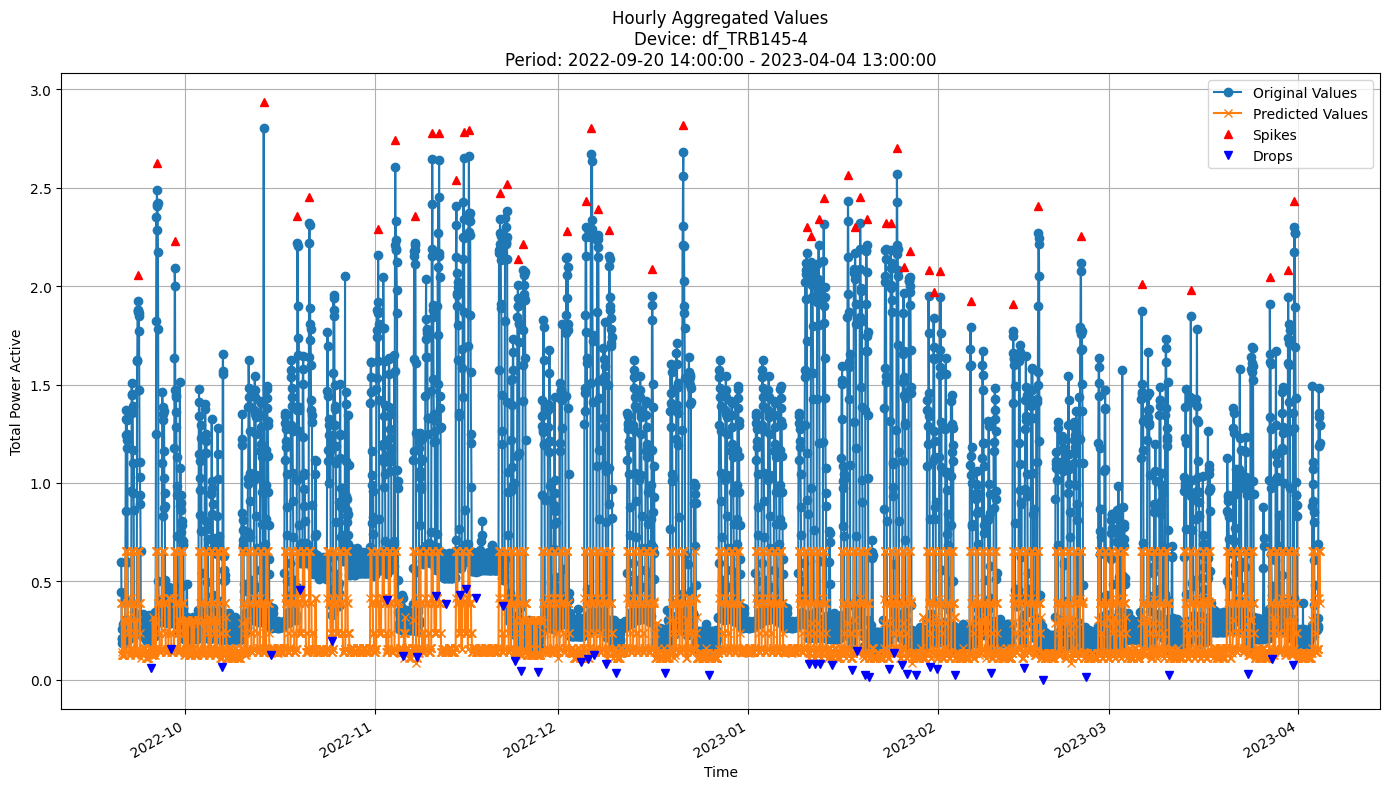


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.5741
MAE: 0.3888
MAPE: 51.2538%

Directional Metrics:
Directional Accuracy: 21.6458%
First-Diff Correlation: 0.3344

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0876
  Recall: 0.2400
  F1 Score: 0.1283
Drops:
  Precision: 0.0035
  Recall: 0.0204
  F1 Score: 0.0060

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2409
  Recall: 0.6600
  F1 Score: 0.3529
Drops:
  Precision: 0.0458
  Recall: 0.2653
  F1 Score: 0.0781


In [49]:
for device_id in incb_all_train_preds.keys():
    y_train = incb_all_train_preds[device_id][-1]['y_true']
    y_pred_train = incb_all_train_preds[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

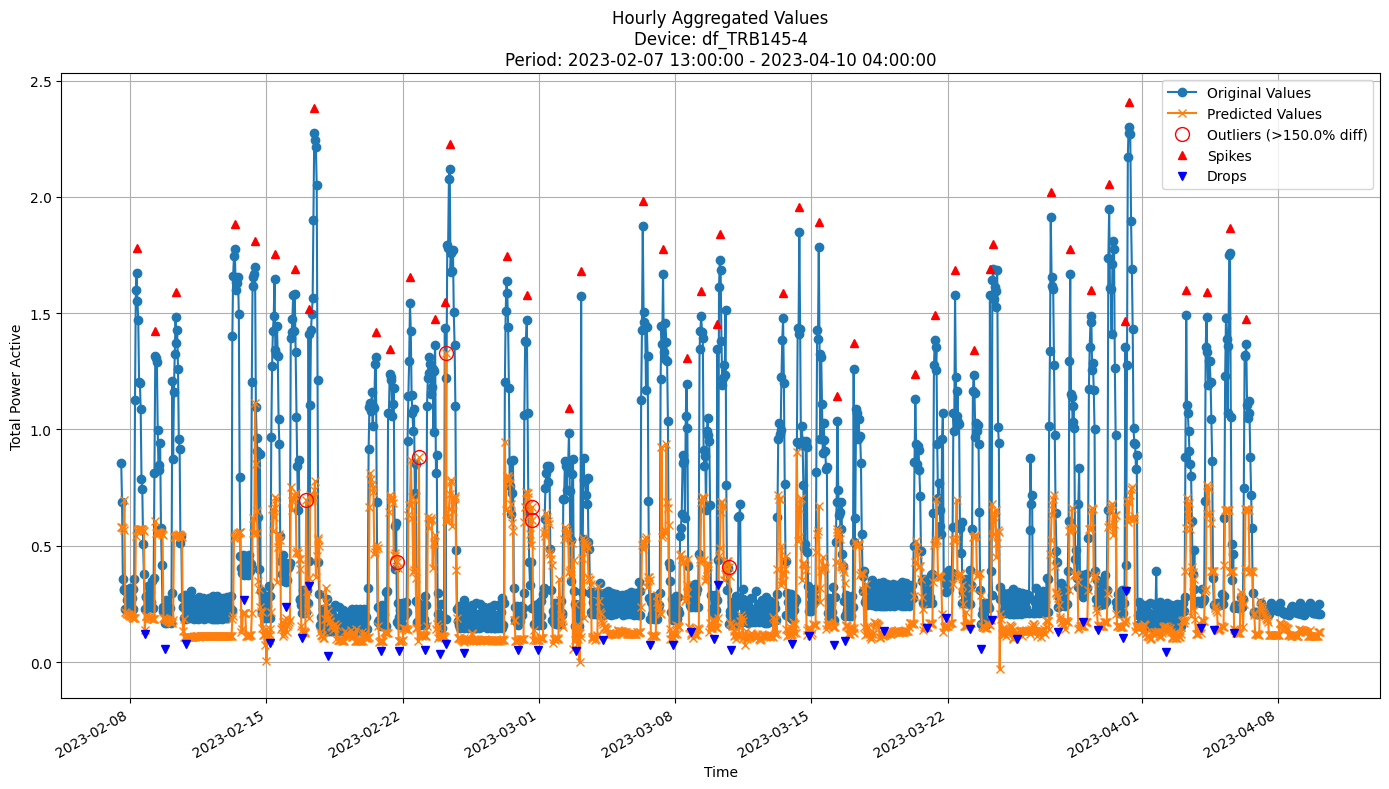


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.4157
MAE: 0.2723
MAPE: 46.6370%

Directional Metrics:
Directional Accuracy: 41.8809%
First-Diff Correlation: 0.1442

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1176
  Recall: 0.0870
  F1 Score: 0.1000
Drops:
  Precision: 0.0294
  Recall: 0.0222
  F1 Score: 0.0253

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3824
  Recall: 0.2826
  F1 Score: 0.3250
Drops:
  Precision: 0.2647
  Recall: 0.2000
  F1 Score: 0.2278


In [50]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in incb_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, incb_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, incb_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

# Test-set Model Evaluation
(`train[-1]` + `valid[-1]`) vs `test`

In [51]:
# Define model classes and params for test-set evaluation
models_classes = [bl_prev, bl_mean, gbdt, rf, hoef, arf_hf, fodt, arf, incb]
models_params = [
    bl_prev_params,
    bl_mean_params,
    gbdt_params,
    rf_params,
    hoef_params,
    arf_hf_params,
    fodt_params,
    arf_params,
    incb_params,
 ]

model_test_results = {}
for model_class, params in zip(models_classes, models_params):
    if model_class in [gbdt, rf, bl_mean]:
        incremental = False
        update_freq = "14D"
        print(f"Model: {model_class.__name__} - update_freq: {update_freq}")
    else:
        incremental = True
        update_freq = "1h"
        print(f"Model: {model_class.__name__} - update_freq: {update_freq}")

    _, test_preds, \
    _, test_metrics = test_set_seq_fit_predict(
        model_class=model_class,
        model_params=params,
        train=train,
        valid=valid,
        test=test,
        incremental=incremental,
        data_freq=DATA_FREQUENCY,
        forecast_horizon=FORECAST_HORIZON,
        features=FEATURES,
        update_freq=update_freq,
        spike_prominence=SPIKE_PROMINENCE,
        normalize_robust=True,
        predict_train=False,
        verbose=True
    )
    model_test_results[model_class.__name__] = {
        "test_preds": test_preds,
        "test_metrics": test_metrics
    }

Model: PreviousValueRegressor - update_freq: 1h


Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 14:00:00+02:00 to 2023-04-10 04:00:00+02:00
Model's memory usage: 0.000366 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-10 06:00:00+02:00 - 2023-05-30 20:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2078
	MAE: 0.0964
	MAPE: 16.4499%

Directional Metrics:
	Directional Accuracy: 48.8468%
	First-Diff Correlation: 0.1843

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
----------------------------------------------

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 14:00:00+02:00 to 2023-04-10 04:00:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2023-04-10 06:00:00+02:00 to 2023-04-24 06:00:00+02:00

-------------------------

Retraining model on data from 2022-09-20 14:00:00+02:00 to 2023-04-24 06:00:00+02:00

Time: 0.01 seconds
Predicting for chunk from 2023-04-24 07:00:00+02:00 to 2023-05-08 07:00:00+02:00

-------------------------

Retraining model on data from 2022-09-20 14:00:00+02:00 to 2023-05-08 07:00:00+02:00

Time: 0.01 seconds
Predicting for chunk from 2023-05-08 08:00:00+02:00 to 2023-05-22 08:00:00+02:00

-------------------------

Retraining model on data from 2022-09-20 14:00:00+02:00 to 2023-05-22 08:00:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2023-05-22 09:00:00+02:00 to 2023-05-30 20:00:00+02:00

-------------------------
Model's memory usage: 0.024338 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-10 06:00:00+02:00 - 2023-05-30 20:00:00+02:00
--------------

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

... (9 outputs left out)

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 14:00:00+02:00 to 2023-04-10 04:00:00+02:00
Model's memory usage: 1217.719398 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-10 06:00:00+02:00 - 2023-05-30 20:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2528
	MAE: 0.1335
	MAPE: 23.1442%

Directional Metrics:
	Directional Accuracy: 62.9325%
	First-Diff Correlation: 0.5765

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2162
		Recall: 0.1778
		F1: 0.1951
	Drops:
		Precision: 0.1622
		Recall: 0.1364
		F1: 0.1481

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.5135
		Recall: 0.4222
		F1: 0.4634
	Drops:
		Precision: 0.3243
		Recall: 0.2727
		F1: 0.2963
-------------------------------------------

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 14:00:00+02:00 to 2023-04-10 04:00:00+02:00
Model's memory usage: 3.551323 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-10 06:00:00+02:00 - 2023-05-30 20:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.4232
	MAE: 0.2748
	MAPE: 48.7137%

Directional Metrics:
	Directional Accuracy: 44.7282%
	First-Diff Correlation: 0.1808

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1429
		Recall: 0.1333
		F1: 0.1379
	Drops:
		Precision: 0.0250
		Recall: 0.0227
		F1: 0.0238

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.4286
		Recall: 0.4000
		F1: 0.4138
	Drops:
		Precision: 0.2500
		Recall: 0.2273
		F1: 0.2381
----------------------------------------------

In [52]:
for model_class in models_classes:
    model_test_results[model_class.__name__]['test_metrics'] = all_time_aggregation_metrics(
        model_test_results[model_class.__name__]['test_metrics'],
        data_freq=DATA_FREQUENCY,
        verbose=False)

# Model Comparison

In [53]:
AGG_LEVEL = "hourly"
METRICS = ["rmse", "mae", "mape", "dir_accuracy", "first_diff_corr"]
PERC_METRICS = ["mape", "dir_accuracy", "first_diff_corr"]
# SPIKES_METRICS = ["spikes_immediate.precision", "spikes_immediate.recall", "spikes_immediate.f1",
#                   "spikes_delayed.precision", "spikes_delayed.recall", "spikes_delayed.f1",
#                   "drops_immediate.precision", "drops_immediate.recall", "drops_immediate.f1",
#                   "drops_delayed.precision", "drops_delayed.recall", "drops_delayed.f1"]
SPIKES_METRICS = ["spikes_immediate.f1", "spikes_delayed.f1",
                  "drops_immediate.f1", "drops_delayed.f1"]

METRICS.extend(SPIKES_METRICS)
PERC_METRICS.extend(SPIKES_METRICS)

## Test results

In [54]:
MODEL_TEST_METRICS = {
    "BL_Prev": model_test_results[bl_prev.__name__]["test_metrics"],
    "BL_Mean": model_test_results[bl_mean.__name__]["test_metrics"],
    "GBDT": model_test_results[gbdt.__name__]["test_metrics"],
    "RandomForest": model_test_results[rf.__name__]["test_metrics"],
    "HoeffdingTree": model_test_results[hoef.__name__]["test_metrics"],
    "ARF_Hoeffding": model_test_results[arf_hf.__name__]["test_metrics"],
    "FastODT": model_test_results[fodt.__name__]["test_metrics"],
    "ARF_FastODT": model_test_results[arf.__name__]["test_metrics"],
    "IncubationBoost": model_test_results[incb.__name__]["test_metrics"],
}

In [55]:
def format_metric(val, is_perc=False):
    if isinstance(val, dict) and "mean" in val and "std" in val:
        mean = val["mean"]
        std = val["std"]
        if is_perc:
            mean = mean * 100
            std = std * 100
        return f"{mean:.3f} ± {std:.3f}"
    if is_perc:
        return f"{val*100:.3f}" if val is not None else None
    return f"{val:.3f}" if val is not None else None

def display_aggregated_results(model_metrics, device_ids, agg_level):
    for device_id in device_ids:
        rows = []
        for model, mdict in model_metrics.items():
            if device_id in mdict and agg_level in mdict[device_id]:
                vals = mdict[device_id][agg_level]
                row = [model]
                for m in METRICS:
                    is_perc = (m in PERC_METRICS)
                    row.append(format_metric(vals.get(m, None), is_perc=is_perc))
                rows.append(row)
        df = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "MAPE (%)", "Directional Accuracy (%)", "First Diff Corr (%)",
                                         "Spikes Immediate F1 (%)", "Spikes Delayed F1 (%)", "Drops Immediate F1 (%)", "Drops Delayed F1 (%)"])
        print(f"\n\nDevice: {device_id} | Aggregation: {agg_level}")
        display(df)

In [56]:
device_ids = set()
for m in MODEL_TEST_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)

print("\n\n============================Hourly Test Results============================")
display_aggregated_results(MODEL_TEST_METRICS, device_ids, AGG_LEVEL)



============================Hourly Test Results============================


Device: df_TRB145-4 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.208 ± 0.000,0.096 ± 0.000,16.450 ± 0.000,48.847 ± 0.000,18.428 ± 0.000,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,100.000 ± 0.000
1,BL_Mean,0.334 ± 0.000,0.213 ± 0.000,52.304 ± 0.000,60.049 ± 0.000,47.497 ± 0.000,31.707 ± 0.000,58.537 ± 0.000,0.000 ± 0.000,17.500 ± 0.000
2,GBDT,0.211 ± 0.000,0.123 ± 0.000,25.442 ± 0.000,55.272 ± 0.000,42.603 ± 0.000,20.253 ± 0.000,55.696 ± 0.000,5.195 ± 0.000,7.792 ± 0.000
3,RandomForest,0.225 ± 0.000,0.131 ± 0.000,27.242 ± 0.000,57.249 ± 0.000,41.375 ± 0.000,10.127 ± 0.000,45.570 ± 0.000,5.195 ± 0.000,15.584 ± 0.000
4,HoeffdingTree,0.281 ± 0.000,0.164 ± 0.000,31.092 ± 0.000,50.494 ± 0.000,35.783 ± 0.000,7.059 ± 0.000,25.882 ± 0.000,2.410 ± 0.000,14.458 ± 0.000
5,ARF_Hoeffding,0.262 ± 0.000,0.150 ± 0.000,28.901 ± 0.000,55.437 ± 0.000,37.264 ± 0.000,7.595 ± 0.000,30.380 ± 0.000,7.792 ± 0.000,20.779 ± 0.000
6,FastODT,0.286 ± 0.000,0.147 ± 0.000,26.118 ± 0.000,52.224 ± 0.000,23.914 ± 0.000,16.923 ± 0.000,46.154 ± 0.000,4.724 ± 0.000,9.449 ± 0.000
7,ARF_FastODT,0.253 ± 0.000,0.133 ± 0.000,23.144 ± 0.000,62.932 ± 0.000,57.653 ± 0.000,19.512 ± 0.000,46.341 ± 0.000,14.815 ± 0.000,29.630 ± 0.000
8,IncubationBoost,0.423 ± 0.000,0.275 ± 0.000,48.714 ± 0.000,44.728 ± 0.000,18.083 ± 0.000,13.793 ± 0.000,41.379 ± 0.000,2.381 ± 0.000,23.810 ± 0.000


## Validation results

In [57]:
MODEL_VALID_METRICS = {
    "BL_Prev": bl_prev_all_time_valid_metrics,
    "BL_Mean": bl_mean_all_time_valid_metrics,
    "GBDT": gbdt_all_time_valid_metrics,
    "RandomForest": rf_all_time_valid_metrics,
    "HoeffdingTree": hoef_all_time_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_time_valid_metrics,
    "FastODT": fodt_all_time_valid_metrics,
    "ARF_FastODT": arf_all_time_valid_metrics,
    "IncubationBoost": incb_all_time_valid_metrics,
}


device_ids = set()
for m in MODEL_VALID_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)


print("\n\n============================Hourly Validation Results============================")
display_aggregated_results(MODEL_VALID_METRICS, device_ids, AGG_LEVEL)



============================Hourly Validation Results============================


Device: df_TRB145-4 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.227 ± 0.042,0.128 ± 0.031,23.862 ± 7.597,39.183 ± 4.839,18.652 ± 19.926,0.000 ± 0.000,85.714 ± 34.993,0.000 ± 0.000,85.253 ± 34.822
1,BL_Mean,0.344 ± 0.064,0.245 ± 0.058,57.051 ± 14.553,61.477 ± 6.660,56.265 ± 14.512,17.514 ± 22.385,44.435 ± 26.854,6.892 ± 8.674,10.500 ± 10.842
2,GBDT,0.246 ± 0.059,0.154 ± 0.048,32.655 ± 6.370,61.839 ± 7.025,37.857 ± 9.551,12.790 ± 12.149,34.631 ± 26.084,7.839 ± 7.823,14.931 ± 14.089
3,RandomForest,0.112 ± 0.011,0.065 ± 0.007,11.950 ± 1.450,78.308 ± 1.368,87.696 ± 3.160,20.511 ± 19.034,28.157 ± 28.338,5.617 ± 7.464,7.121 ± 10.756
4,HoeffdingTree,0.318 ± 0.048,0.202 ± 0.039,39.836 ± 4.818,50.042 ± 3.119,30.476 ± 9.451,6.402 ± 6.117,24.525 ± 15.673,0.794 ± 1.944,8.361 ± 9.959
5,ARF_Hoeffding,0.269 ± 0.055,0.186 ± 0.040,42.208 ± 8.156,57.537 ± 3.807,46.473 ± 9.983,18.638 ± 15.813,34.171 ± 27.964,7.995 ± 8.037,15.790 ± 13.215
6,FastODT,0.324 ± 0.057,0.184 ± 0.042,33.251 ± 7.785,49.000 ± 5.359,23.843 ± 5.438,13.833 ± 18.741,22.747 ± 18.439,3.810 ± 5.325,10.397 ± 12.562
7,ARF_FastODT,0.295 ± 0.061,0.182 ± 0.051,36.770 ± 8.669,55.941 ± 2.609,46.959 ± 12.783,14.682 ± 14.756,41.181 ± 27.671,2.977 ± 3.720,15.628 ± 14.061
8,IncubationBoost,0.468 ± 0.100,0.319 ± 0.084,45.703 ± 2.923,45.849 ± 5.430,26.602 ± 10.402,5.872 ± 5.525,24.043 ± 14.917,1.504 ± 3.683,11.333 ± 10.602


### By-period validation results

In [58]:
MODEL_VALID_PERIOD_METRICS = {
    "BL_Mean": bl_prev_valid_period_metrics,
    "BL_Prev": bl_mean_valid_period_metrics,
    "GBDT": gbdt_valid_period_metrics,
    "RandomForest": rf_valid_period_metrics,
    "HoeffdingTree": hoef_all_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_valid_metrics,
    "FastODT": fodt_all_valid_metrics,
    "ARF_FastODT": arf_all_valid_metrics,
    "IncubationBoost": incb_all_valid_metrics,
}

def show_per_period_metric_tables(device_ids, MODEL_VALID_PERIOD_METRICS, AGG_LEVEL, metric_name, display_gain=True):
    """
    Display per-period metric tables and gain/drop tables for a given metric.
    Args:
        device_ids: List of device IDs to display metrics for.
        MODEL_VALID_PERIOD_METRICS: Dictionary containing model period metrics.
        AGG_LEVEL: Aggregation level (e.g., "hourly").
        metric_name: The name of the metric to display.
        display_gain: Whether to display gain/drop tables.
    """
    for device_id in device_ids:
        period_vals = {}
        n_periods = None
        for model, mdict in MODEL_VALID_PERIOD_METRICS.items():
                if metric_name in PERC_METRICS:
                    vals = [period[AGG_LEVEL][metric_name]*100 for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                else:
                    vals = [period[AGG_LEVEL][metric_name] for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                n_periods = len(vals)
        if not period_vals:
            continue

        df_metric = pd.DataFrame(period_vals)
        df_metric.index = [f"Period {i+1}" for i in range(n_periods)]
        df_metric['Agg. Per Period'] = df_metric.astype(float).mean(axis=1)

        metric_label = f"{metric_name.upper()} (%)" if metric_name in PERC_METRICS else metric_name.upper()
        print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL} | {metric_label} per period")
        display(df_metric)


        if display_gain:
            # Absolute gain/drop
            abs_gain = df_metric.astype(float).diff().iloc[1:]
            abs_gain = abs_gain.applymap(lambda v: f"{v:.3f}")
            abs_gain.index = [f"{df_metric.index[i]} - {df_metric.index[i-1]}" for i in range(1, len(df_metric))]
            print(f"\nAbsolute gain/drop in {metric_label}:")
            display(abs_gain)
            # Percentage gain/drop
            # pct_gain = df_metric.astype(float).pct_change().iloc[1:] * 100
            # pct_gain = pct_gain.applymap(lambda v: f"{v:.3f}")
            # pct_gain.index = abs_gain.index
            # print(f"\nPercentage gain/drop in {metric_label} (lower is better):")
            # display(pct_gain)

#### Directional accuracy (higher is better)


In [59]:
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="dir_accuracy",
    display_gain=True
)


Device: df_TRB145-4 | Aggregation: hourly | DIR_ACCURACY (%) per period


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,34.426,62.146,54.694,59.165,44.709,54.098,45.455,56.334,41.133,50.240000
Period 2,39.642,61.997,60.209,57.973,52.757,59.762,42.176,53.502,43.666,52.409333
Period 3,50.075,75.708,75.112,71.237,50.820,64.680,43.219,61.699,53.651,60.689000
Period 4,36.662,61.848,64.232,66.021,54.545,58.867,57.228,53.502,47.392,55.588556
Period 5,35.768,53.353,66.319,67.362,51.267,58.122,55.142,56.185,40.089,53.734111
Period 6,37.407,60.060,52.608,54.098,49.180,54.247,49.031,54.396,41.282,50.256556
Period 7,40.299,55.224,59.701,55.224,47.015,52.985,50.746,55.970,53.731,52.321667



Absolute gain/drop in DIR_ACCURACY (%):


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,5.216,-0.149,5.515,-1.192,8.048,5.664,-3.279,-2.832,2.533,2.169
Period 3 - Period 2,10.433,13.711,14.903,13.264,-1.937,4.918,1.043,8.197,9.985,8.280
Period 4 - Period 3,-13.413,-13.860,-10.880,-5.216,3.725,-5.813,14.009,-8.197,-6.259,-5.100
Period 5 - Period 4,-0.894,-8.495,2.087,1.341,-3.278,-0.745,-2.086,2.683,-7.303,-1.854
Period 6 - Period 5,1.639,6.707,-13.711,-13.264,-2.087,-3.875,-6.111,-1.789,1.193,-3.478
Period 7 - Period 6,2.892,-4.836,7.093,1.126,-2.165,-1.262,1.715,1.574,12.449,2.065


#### MAPE (lower is better)

In [60]:
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="mape",
    display_gain=True
)


Device: df_TRB145-4 | Aggregation: hourly | MAPE (%) per period


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,17.513,40.679,26.876,20.907,29.159,27.915,27.001,35.030,47.142,30.246889
Period 2,23.358,52.843,40.622,30.162,40.916,52.029,34.468,46.972,46.712,40.898000
Period 3,19.095,53.377,24.120,22.241,37.458,37.531,28.148,27.066,45.567,32.733667
Period 4,32.108,57.060,41.796,37.737,43.553,51.873,44.840,34.260,46.833,43.340000
Period 5,32.711,61.909,32.412,35.376,41.356,47.749,35.734,32.982,48.457,40.965111
Period 6,30.593,44.700,35.090,35.095,42.022,38.630,41.515,28.799,46.388,38.092444
Period 7,11.654,88.786,27.674,25.460,44.389,39.729,21.048,52.281,38.820,38.871222



Absolute gain/drop in MAPE (%):


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,5.845,12.164,13.746,9.255,11.757,24.114,7.467,11.942,-0.430,10.651
Period 3 - Period 2,-4.263,0.534,-16.502,-7.921,-3.458,-14.498,-6.320,-19.906,-1.145,-8.164
Period 4 - Period 3,13.013,3.683,17.676,15.496,6.095,14.342,16.692,7.194,1.266,10.606
Period 5 - Period 4,0.603,4.849,-9.384,-2.361,-2.197,-4.124,-9.106,-1.278,1.624,-2.375
Period 6 - Period 5,-2.118,-17.209,2.678,-0.281,0.666,-9.119,5.781,-4.183,-2.069,-2.873
Period 7 - Period 6,-18.939,44.086,-7.416,-9.635,2.367,1.099,-20.467,23.482,-7.568,0.779


#### RMSE (lower is better)

In [61]:
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="rmse",
    display_gain=True
)


Device: df_TRB145-4 | Aggregation: hourly | RMSE per period


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.257,0.453,0.349,0.297,0.380,0.346,0.356,0.384,0.592,0.379333
Period 2,0.254,0.401,0.291,0.272,0.390,0.315,0.371,0.382,0.576,0.361333
Period 3,0.179,0.277,0.196,0.174,0.294,0.208,0.262,0.235,0.439,0.251556
Period 4,0.271,0.319,0.277,0.272,0.326,0.301,0.396,0.304,0.532,0.333111
Period 5,0.238,0.292,0.211,0.244,0.283,0.278,0.310,0.232,0.429,0.279667
Period 6,0.242,0.284,0.233,0.235,0.303,0.254,0.346,0.246,0.424,0.285222
Period 7,0.147,0.386,0.163,0.160,0.248,0.178,0.225,0.278,0.283,0.229778



Absolute gain/drop in RMSE:


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-0.003,-0.052,-0.058,-0.025,0.010,-0.031,0.015,-0.002,-0.016,-0.018
Period 3 - Period 2,-0.075,-0.124,-0.095,-0.098,-0.096,-0.107,-0.109,-0.147,-0.137,-0.110
Period 4 - Period 3,0.092,0.042,0.081,0.098,0.032,0.093,0.134,0.069,0.093,0.082
Period 5 - Period 4,-0.033,-0.027,-0.066,-0.028,-0.043,-0.023,-0.086,-0.072,-0.103,-0.053
Period 6 - Period 5,0.004,-0.008,0.022,-0.009,0.020,-0.024,0.036,0.014,-0.005,0.006
Period 7 - Period 6,-0.095,0.102,-0.070,-0.075,-0.055,-0.076,-0.121,0.032,-0.141,-0.055
